# NB-10 · Stage 10 — Threshold calibration and evaluation

**Project:** HiDMamba, hierarchical distillation for 12-lead ECG (PTB-XL, 100 Hz)
**Runtime:** Kaggle GPU (T4). Inference on 4,400 records (about 1 minute), threshold search on CPU, latency benchmark (about 5 minutes). Total about 10 to 15 minutes.

Synopsis, Stage 10: *grid-search per-label decision thresholds on the validation fold to maximize F1; evaluate the full standalone Chief Resident (plus the offline prototype lookup) on the held-out test fold exactly once; benchmark both core-model and end-to-end latency.*

### The protocol, in one paragraph
Everything that could be tuned is tuned on **fold 9** and then **frozen to disk** (`frozen_config.json`, with file hashes) before any fold-10 record is read: the Platt maps, the per-label F1 thresholds, the retrieval mixing weight. Only then are the fold-10 signals passed through the models, and the fold-10 labels are loaded **once**, through a function that counts its own calls. Nothing is changed after the labels are seen: the notebook has no cell that re-fits, re-tunes or re-selects on fold 10, and a check at the end verifies the counter. The test number is therefore not threshold-tuned on test data, which is what Section 3.4 of the synopsis requires.

### What is evaluated
| System | What it is | Role |
|---|---|---|
| **Chief Resident** | the deployed 0.89 M-parameter student of Stage 8 (patchifier, one bidirectional Mamba block, head), Platt probabilities, frozen per-label thresholds | **headline system** (the "standalone deployable Chief Resident" of the synopsis) |
| **CR + retrieval** | the same probabilities mixed with the neighbour vote of the Stage-9 index (`index_trainval`), mixing weight chosen on fold 9 | secondary system: does the prototype lookup add accuracy, beyond serving as the explanation? |
| DEAN (teacher) | the frozen 11.5 M-parameter teacher with its own head, calibrated and thresholded the same way | reference |
| kNN retrieval | the neighbour vote on its own | reference |

The prototype lookup also has its **own** evaluation as an explanation: do the retrieved ECGs share the predicted diagnoses, and does neighbour agreement tell a right prediction from a wrong one (Section 11).

### Inputs (attach these Datasets)
| Dataset | Files used |
|---|---|
| `chief-resident-v1` (Stage 8) | `chief_resident_deploy.pt`, `cr_lib.py`; optional `cr_logits_val.npy`, `cr_metrics.json` (cross-checks) |
| `dean-finetuned-v2` (Stage 3) | `dean_finetuned.pt`, `split_idx.npz`, `dean_lib.py`, `eval_lib.py` |
| `ptbxl-processed-v1` (Stage 1) | `ptbxl_100hz.npy`, `labels_multihot.csv` |
| `prototype-index-v1` (Stage 9) | `index_train.faiss`, `index_trainval.faiss`, `prototype_meta.npz`, `prototype_config.json`, `proto_lib.py`; optional `dean_emb_val.npy`, `knn_scores_val.npy` |

### Outputs (`/kaggle/working`)
`frozen_config.json` (every number fixed on fold 9), `hidmamba_infer.py` (the deployment pipeline of Step 11, tested here against the batch evaluation), `test_predictions.npz`, `test_explanations.npz`, `stage10_metrics.json`, `tables/*.csv`, `figures/*.png|pdf` (20 figures, 7.2 in wide, 300 dpi).

### Decisions that interpret the plan
* **Headline = the standalone Chief Resident.** The synopsis deploys the Chief Resident and uses the index to *explain* its prediction (Step 11, item 4). The retrieval-fused score is therefore reported as a second, clearly labelled system and never replaces the headline.
* **Per-label thresholds on a fine grid, ties to the middle.** The grid is 0.005 to 0.99 (finer at low probabilities, where rare labels live). Among equally good thresholds the middle of the plateau is taken, which is more stable than the first. A label with fewer than 10 positives in fold 9 gets the single pooled threshold that maximises macro-F1 over the other labels, because a per-label threshold fitted on a handful of positives is noise. Section 5 measures how stable the thresholds are and whether per-label tuning pays off on fold 9 itself (cross-fit).
* **Labels that enter the macro averages** are those with at least 10 positives in **both** fold 9 and fold 10 (the same reliability rule as every earlier stage, applied to both folds). Labels left out are listed, and a second macro over every label with at least one test positive is given as a sensitivity.
* **Pre-declared claims.** The tolerances (0.01 AUC, 0.02 F1) and the list of claims are written in the configuration cell, before any result exists, and the verdict rule is the one of Stage 8 (supported if the interval lies on the claimed side, contradicted if it lies on the other, otherwise not supported).
* **Latency** is measured with the library code path of the deployed models (not the faster training-time scan), on the CPU with one thread and with all threads, and on the GPU if there is one; the end-to-end figure includes the DEAN forward pass that the prototype lookup needs, because the index is built over DEAN embeddings (Stage 9).

## 0. Environment

In [1]:
import os, sys, glob, json, time, math, copy, random, shutil, warnings, platform, importlib, subprocess, hashlib
from collections import OrderedDict
from contextlib import nullcontext

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import rankdata, spearmanr
from sklearn.metrics import average_precision_score, roc_curve, precision_recall_curve

warnings.filterwarnings('ignore', category=UserWarning)
NB_T0 = time.time()
ON_KAGGLE = os.path.exists('/kaggle/working')
WORK = '/kaggle/working' if ON_KAGGLE else os.path.abspath('./working')
INPUT_ROOT = os.environ.get('NB_INPUT_ROOT', '/kaggle/input')
os.makedirs(WORK, exist_ok=True); os.chdir(WORK)
FIG_DIR, TAB_DIR = os.path.join(WORK, 'figures'), os.path.join(WORK, 'tables')
for d in (FIG_DIR, TAB_DIR): os.makedirs(d, exist_ok=True)
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = dev.type == 'cuda'

def amp():
    return torch.autocast('cuda', dtype=torch.float16) if USE_AMP else nullcontext()

def find_art(name, exclude=()):
    hits = sorted(glob.glob(f'{WORK}/**/{name}', recursive=True)) + sorted(glob.glob(f'{INPUT_ROOT}/**/{name}', recursive=True))
    hits = [h for h in hits if not any(e in h for e in exclude)]
    return hits[0] if hits else None

def find_one(name, hint=''):
    p = find_art(name)
    if p is None: raise FileNotFoundError(f'{name} not found. Attach the Dataset {hint or "that contains it"}.')
    return p

def sha256(path, n=1 << 20):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for c in iter(lambda: f.read(n), b''): h.update(c)
    return h.hexdigest()

VERSIONS = {'python': platform.python_version(), 'torch': torch.__version__, 'numpy': np.__version__, 'pandas': pd.__version__}
print(VERSIONS, '| device', dev, '| work', WORK)

{'python': '3.13.15', 'torch': '2.11.0+cu128', 'numpy': '2.1.3', 'pandas': '2.3.3'} | device cuda | work /kaggle/working


## 1. Configuration
Everything that decides how a result is read is fixed here, before any number exists: the tolerances, the mixing-weight grid, the bootstrap size and the latency protocol.

In [2]:
CFG = dict(
    seed=42, min_pos=10, n_boot=1000, n_boot_thr=200,
    margin_auc=0.01, margin_f1=0.02, speed_claim=5.0,                      # pre-declared tolerances (see the claims table)
    alphas=[round(i / 10, 1) for i in range(11)],                          # weight of the retrieval vote in the mixed probability
    k_proto=5, bs_infer=128,
    lat_batches=[1, 8, 64], lat_reps={1: 100, 8: 30, 64: 10}, lat_warm={1: 10, 8: 5, 64: 3}, lat_dean_cpu_max_bs=8, e2e_n=100,
    n_examples=3, strict=True,
)
print(CFG)

{'seed': 42, 'min_pos': 10, 'n_boot': 1000, 'n_boot_thr': 200, 'margin_auc': 0.01, 'margin_f1': 0.02, 'speed_claim': 5.0, 'alphas': [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], 'k_proto': 5, 'bs_infer': 128, 'lat_batches': [1, 8, 64], 'lat_reps': {1: 100, 8: 30, 64: 10}, 'lat_warm': {1: 10, 8: 5, 64: 3}, 'lat_dean_cpu_max_bs': 8, 'e2e_n': 100, 'n_examples': 3, 'strict': True}


## 2. Libraries
`cr_lib.py` (Chief Resident), `dean_lib.py` (encoder), `eval_lib.py` (metrics, Platt) and `proto_lib.py` (index) come from the Datasets of the stages that wrote them, so every model and metric is the object of the earlier stage. `hidmamba_infer.py` is written below: it is the deployment pipeline (Step 11) and is what the latency benchmark times.

In [3]:
%%writefile hidmamba_infer.py
"""Deployment pipeline of HiDMamba (stage 10, step 11 of the synopsis).

new ECG -> deployed Chief Resident (patchifier -> one bidirectional Mamba block -> head) -> Platt probabilities -> frozen per-label thresholds
        -> frozen DEAN embedding -> exact FAISS inner-product search -> nearest prototype ECGs as the explanation.
Optionally the retrieval votes are fused with the Chief Resident probabilities (the secondary system of stage 10).
Everything needed is a file written by stages 3, 8, 9 and 10; nothing is trained here.
"""
import os, json, time
import numpy as np
import torch


def _sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


class HiDMambaPipeline:
    def __init__(self, paths, device='cpu', which='trainval', k_proto=5, use_amp=None):
        """paths: dict with 'deploy' (chief_resident_deploy.pt), 'dean' (dean_finetuned.pt), 'frozen' (frozen_config.json), 'index_root' (folder of stage 9)."""
        import cr_lib, dean_lib, proto_lib
        self.proto_lib = proto_lib
        self.dev = torch.device(device)
        self.amp = (self.dev.type == 'cuda') if use_amp is None else bool(use_amp)
        self.k_proto = int(k_proto)
        fz = json.load(open(paths['frozen']))
        self.fz = fz
        pay = torch.load(paths['deploy'], map_location='cpu', weights_only=False)
        self.cr = cr_lib.ChiefResidentDeploy(pay['enc_cfg'], pay['width'], pay['n_sup'], pay['n_sub'], pay['head_drop'], pay['sub_hidden']).to(self.dev)
        self.cr.load_state_dict(pay['deploy'], strict=True)
        self.cr.eval()
        self.labels = list(pay['labels'])
        assert self.labels == list(fz['labels']), 'label order of the deployed model and of the frozen configuration differ'
        self.mu = np.array(pay['norm_mean'], np.float32)[None, :, None]
        self.sd = np.array(pay['norm_std'], np.float32)[None, :, None]
        ck = torch.load(paths['dean'], map_location='cpu', weights_only=False)
        cfg = dict(ck['enc_config']); cfg['grad_ckpt'] = False
        self.dean = dean_lib.DEANEncoder(**cfg).to(self.dev)
        self.dean.load_state_dict(ck['encoder'])
        self.dean.eval()
        for p in list(self.dean.parameters()) + list(self.cr.parameters()):
            p.requires_grad_(False)
        s = fz['systems']
        self.a, self.b, self.thr = [np.array(s['chief_resident'][k], np.float64) for k in ('platt_a', 'platt_b', 'thresholds')]
        self.knn_a, self.knn_b = np.array(s['knn']['platt_a'], np.float64), np.array(s['knn']['platt_b'], np.float64)
        self.alpha = float(s['fusion']['alpha']); self.thr_f = np.array(s['fusion']['thresholds'], np.float64)
        self.ret = proto_lib.Retriever(paths['index_root'], which)
        self.knn_k, self.knn_tau = int(self.ret.cfg['k']), self.ret.cfg['tau']

    def _sync(self):
        if self.dev.type == 'cuda':
            torch.cuda.synchronize()

    def _amp(self):
        return torch.autocast('cuda', dtype=torch.float16) if self.amp else torch.autocast('cpu', enabled=False)

    @torch.no_grad()
    def predict(self, x, explain=True, fuse=False, timings=None):
        """x: raw signal (12, T) or (B, 12, T) at 100 Hz, in the units of the training data. Returns one dict per record."""
        x = np.asarray(x, np.float32)
        if x.ndim == 2:
            x = x[None]
        tm = timings if timings is not None else {}

        def tick(name, t):
            self._sync(); t2 = time.perf_counter(); tm[name] = tm.get(name, 0.0) + (t2 - t) * 1e3; return t2
        t = time.perf_counter()
        xt = torch.from_numpy((np.nan_to_num(x) - self.mu) / self.sd).to(self.dev)
        t = tick('preprocess', t)
        logits = self.cr(xt).float().cpu().numpy().astype(np.float64)
        t = tick('chief_resident', t)
        p = _sigmoid(logits * self.a + self.b)
        pos = p >= self.thr
        t = tick('calibrate', t)
        D = I = None; pf = posf = None
        if explain or fuse:
            with self._amp():
                z = self.dean(xt).float().mean(1)
            z = z.cpu().numpy()
            t = tick('dean_embedding', t)
            k = self.knn_k if fuse else self.k_proto
            D, I = self.ret.search(z, k)
            t = tick('retrieval', t)
            if fuse:
                S = self.proto_lib.knn_scores(D, I, self.ret.Y, k, self.knn_tau)
                zl = np.log(np.clip(S, 1e-3, 1 - 1e-3) / (1 - np.clip(S, 1e-3, 1 - 1e-3)))
                pf = (1 - self.alpha) * p + self.alpha * _sigmoid(zl * self.knn_a + self.knn_b)
                posf = pf >= self.thr_f
                t = tick('fusion', t)
        out = []
        for i in range(len(x)):
            r = dict(probabilities=dict(zip(self.labels, p[i].tolist())), labels=[l for l, f in zip(self.labels, pos[i]) if f], logits=logits[i])
            if D is not None:
                kk = self.k_proto
                r['prototypes'] = [dict(ecg_id=int(self.ret.ecg_id[I[i, j]]), similarity=float(D[i, j]),
                                        labels=[l for l, f in zip(self.labels, self.ret.Y[I[i, j]] > 0) if f]) for j in range(kk)]
            if pf is not None:
                r['fused_probabilities'] = dict(zip(self.labels, pf[i].tolist())); r['fused_labels'] = [l for l, f in zip(self.labels, posf[i]) if f]
            out.append(r)
        tick('assemble', t)
        return out

Writing hidmamba_infer.py


In [4]:
sys.path.insert(0, WORK)
for nm, hint in (('eval_lib.py', 'dean-finetuned-v2'), ('dean_lib.py', 'dean-finetuned-v2'), ('cr_lib.py', 'chief-resident-v1'), ('proto_lib.py', 'prototype-index-v1')):
    src = find_one(nm, hint)
    if os.path.abspath(src) != os.path.join(WORK, nm): shutil.copy(src, os.path.join(WORK, nm))
try:
    import faiss
except Exception:
    print('faiss not installed, trying pip install faiss-cpu ...')
    r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'faiss-cpu'], capture_output=True, text=True)
    print(r.stdout[-300:], r.stderr[-300:])
import eval_lib, dean_lib, cr_lib, proto_lib
for m in (eval_lib, dean_lib, cr_lib, proto_lib): importlib.reload(m)
import hidmamba_infer; importlib.reload(hidmamba_infer)
from eval_lib import sigmoid, fit_calibration, reliability
import proto_lib as PL
print('faiss available:', PL.HAVE_FAISS, '|', (PL.faiss.__version__ if PL.HAVE_FAISS else 'numpy reference index will be used'))

# training-time scan (equal to the library scan, checked below) used for the evaluation passes; the latency benchmark restores the library scan
def fast_scan(u, dt, A, Bm, Cm, D):
    with torch.autocast(device_type='cuda', enabled=False):
        u, dt, Bm, Cm = u.float(), dt.float(), Bm.float(), Cm.float()
        h = torch.zeros(u.shape[0], u.shape[2], A.shape[1], device=u.device)
        ys = []
        for u_t, dt_t, B_t, C_t in zip(u.unbind(1), dt.unbind(1), Bm.unbind(1), Cm.unbind(1)):
            h = torch.exp(dt_t.unsqueeze(-1) * A) * h + (dt_t * u_t).unsqueeze(-1) * B_t.unsqueeze(1)
            ys.append(torch.einsum('bdn,bn->bd', h, C_t))
        return torch.stack(ys, 1) + u * D
REF_SCAN = dean_lib.selective_scan
_g = torch.Generator().manual_seed(0)
_u, _dt = torch.randn(2, 40, 8, generator=_g), torch.rand(2, 40, 8, generator=_g) * 0.5
_A, _B, _C = -(torch.rand(8, 4, generator=_g) + 1), torch.randn(2, 40, 4, generator=_g), torch.randn(2, 40, 4, generator=_g)
assert torch.allclose(REF_SCAN(_u, _dt, _A, _B, _C, torch.ones(8)), fast_scan(_u, _dt, _A, _B, _C, torch.ones(8)), atol=1e-4)
def use_scan(fast):
    dean_lib.selective_scan = fast_scan if fast else REF_SCAN
use_scan(True)
print('fast scan equals the library scan')

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.lines import Line2D
W2, W1 = 7.2, 3.5
mpl.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 300, 'font.family': 'serif', 'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7.5,
    'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5, 'legend.fontsize': 6.5, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.4, 'legend.frameon': False, 'pdf.fonttype': 42, 'axes.linewidth': 0.6,
    'xtick.major.width': 0.6, 'ytick.major.width': 0.6, 'lines.linewidth': 1.0,
})
SUPER = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
SUPER_COL = {'NORM': '#009E73', 'MI': '#D55E00', 'STTC': '#0072B2', 'CD': '#CC79A7', 'HYP': '#E69F00'}
FAMILY = {
    'AMI': 'MI', 'IMI': 'MI', 'LMI': 'MI', 'PMI': 'MI', 'ISCA': 'STTC', 'ISCI': 'STTC', 'ISC_': 'STTC', 'NST_': 'STTC',
    'CLBBB': 'CD', 'CRBBB': 'CD', 'ILBBB': 'CD', 'IRBBB': 'CD', 'IVCD': 'CD', 'LAFB/LPFB': 'CD', 'WPW': 'CD', '_AVB': 'CD',
    'LAO/LAE': 'HYP', 'LVH': 'HYP', 'RAO/RAE': 'HYP', 'RVH': 'HYP', 'SEHYP': 'HYP'}
fam_col = lambda l: SUPER_COL[l] if l in SUPER_COL else SUPER_COL[FAMILY[l]]
C_CR, C_DEAN, C_KNN, C_FUS = '#009E73', '#333333', '#0072B2', '#D55E00'
SYS_COL = OrderedDict([('Chief Resident', C_CR), ('DEAN (teacher)', C_DEAN), ('kNN retrieval', C_KNN), ('CR + retrieval', C_FUS)])
def save_fig(fig, name):
    for a_ in fig.axes:
        for axis in (a_.xaxis, a_.yaxis):
            if axis.get_scale() == 'log': axis.set_minor_formatter(mpl.ticker.NullFormatter())
    fig.savefig(os.path.join(FIG_DIR, name + '.png'), bbox_inches='tight', pad_inches=0.04)
    fig.savefig(os.path.join(FIG_DIR, name + '.pdf'), bbox_inches='tight', pad_inches=0.04)
    plt.show()
def panel(ax, s):
    ax.text(-0.02, 1.04, s, transform=ax.transAxes, fontsize=8.5, fontweight='bold', va='bottom', ha='right')
CHECKS = []
def check(name, ok, detail='', level='fail'):
    CHECKS.append(dict(check=name, status='PASS' if ok else ('FAIL' if level == 'fail' else 'WARN'), detail=str(detail)))
    print(f'[{"ok" if ok else level.upper()}] {name}' + (f': {detail}' if detail != '' else ''))
    return ok

faiss not installed, trying pip install faiss-cpu ...
 
faiss available: True | 1.15.1
fast scan equals the library scan


## 3. Labels, split, signals and the deployed artefacts
The validation labels are loaded here. The test labels are **not**: they sit behind `get_test_labels()`, which counts its calls, and the only call is in Section 7, after the configuration is frozen. The signals of fold 10 are not read before that point either.

In [5]:
ck = torch.load(find_one('dean_finetuned.pt', 'dean-finetuned-v2'), map_location='cpu', weights_only=False)
LABELS = list(ck['label_columns']); ENC_CFG = dict(ck['enc_config']); ENC_CFG['grad_ckpt'] = False
assert LABELS[:5] == SUPER and len(LABELS) == 26
SUB = LABELS[5:]
P_DEPLOY = find_one('chief_resident_deploy.pt', 'chief-resident-v1')
PAY = torch.load(P_DEPLOY, map_location='cpu', weights_only=False)
MU, SD = np.array(PAY['norm_mean'], np.float32), np.array(PAY['norm_std'], np.float32)
check('deployed model and DEAN share the label order and the normalisation', list(PAY['labels']) == LABELS and np.allclose(MU, np.array(ck['norm_mean'], np.float32)) and np.allclose(SD, np.array(ck['norm_std'], np.float32)))
check('deploy file holds no training-only parameter', not any(k.startswith(cr_lib.TRAIN_ONLY_PREFIXES) for k in PAY['deploy']))
split = np.load(find_one('split_idx.npz', 'dean-finetuned-v2'), allow_pickle=True)
tr_idx, va_idx, te_idx = split['train_idx'], split['val_idx'], split['test_idx']
df = pd.read_csv(find_one('labels_multihot.csv', 'ptbxl-processed-v1')); df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
fold = df[next(c for c in ('strat_fold', 'fold') if c in df.columns)].values.astype(int)
ecg_id = df['ecg_id'].values if 'ecg_id' in df.columns else np.arange(len(df))
_YALL = df[LABELS].values.astype(np.float32)
Y_tr, Y_va = _YALL[tr_idx], _YALL[va_idx]
NTR, NVA, NTE = len(tr_idx), len(va_idx), len(te_idx)
_TEST_ACCESS = dict(n=0, when=None)
def _make_getter(Yfull, idx):
    def get_test_labels():
        _TEST_ACCESS['n'] += 1; _TEST_ACCESS['when'] = time.time()
        return Yfull[idx].copy()
    return get_test_labels
get_test_labels = _make_getter(_YALL, te_idx)
del _YALL
check('split: train = folds 1-8, validation = fold 9, test = fold 10', np.array_equal(tr_idx, np.where(fold <= 8)[0]) and np.array_equal(va_idx, np.where(fold == 9)[0]) and np.array_equal(te_idx, np.where(fold == 10)[0]))
check('the three folds are disjoint', len(set(tr_idx) | set(va_idx) | set(te_idx)) == NTR + NVA + NTE)
sig = np.load(find_one('ptbxl_100hz.npy', 'ptbxl-processed-v1'), mmap_mode='r')
if sig.ndim == 3 and sig.shape[1] != 12 and sig.shape[2] == 12: sig = np.transpose(sig, (0, 2, 1))
assert len(df) == sig.shape[0]
REL_VAL = Y_va.sum(0) >= CFG['min_pos']
print(f'train {NTR} | validation {NVA} | test {NTE} | labels with >= {CFG["min_pos"]} validation positives: {int(REL_VAL.sum())}/26 | below: {[LABELS[i] for i in np.where(~REL_VAL)[0]]}')
IDX_ROOT = os.path.dirname(find_one('prototype_config.json', 'prototype-index-v1'))
if not PL.HAVE_FAISS and not os.path.exists(os.path.join(IDX_ROOT, 'index_trainval.faiss.npy')):
    raise RuntimeError('The Stage-9 index is a FAISS file and faiss-cpu could not be installed: turn Internet on in the notebook settings (pip install faiss-cpu) and run again.')
PCFG = json.load(open(os.path.join(IDX_ROOT, 'prototype_config.json')))
check('the Stage-9 index was built over the same label order', list(PCFG['labels']) == LABELS)
print('retrieval configuration of Stage 9:', {k: PCFG[k] for k in ('variant', 'n_comp', 'eps', 'k', 'tau', 'dim', 'n_train', 'n_trainval')})

[ok] deployed model and DEAN share the label order and the normalisation
[ok] deploy file holds no training-only parameter
[ok] split: train = folds 1-8, validation = fold 9, test = fold 10
[ok] the three folds are disjoint
train 17418 | validation 2183 | test 2198 | labels with >= 10 validation positives: 21/26 | below: ['PMI', 'ILBBB', 'WPW', 'RVH', 'SEHYP']
[ok] the Stage-9 index was built over the same label order
retrieval configuration of Stage 9: {'variant': 'whiten', 'n_comp': 256, 'eps': 1.0, 'k': 100, 'tau': 0.2, 'dim': 256, 'n_train': 17418, 'n_trainval': 19601}


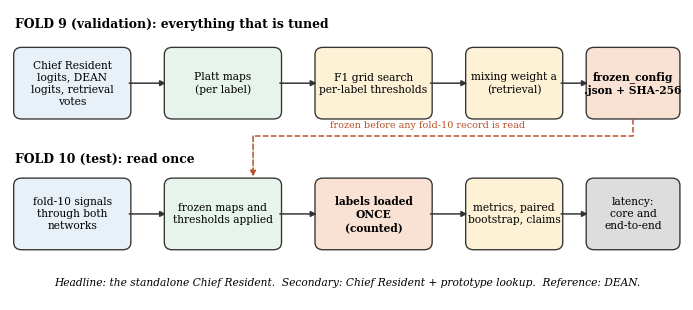

In [6]:
# ---- Figure 1: the protocol ---------------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(W2, 3.1)); ax.set_xlim(0, 100); ax.set_ylim(0, 46); ax.axis('off'); ax.grid(False)
def box(x, y, w, h, txt, fc, ec='#333333', fs=6.4, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.25,rounding_size=1.2', fc=fc, ec=ec, lw=0.8))
    ax.text(x + w / 2, y + h / 2, txt, ha='center', va='center', fontsize=fs, fontweight='bold' if bold else 'normal', linespacing=1.25)
def arrow(x0, y0, x1, y1, col='#333333', ls='-'):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='-|>', color=col, lw=0.9, ls=ls, shrinkA=0, shrinkB=0))
ax.text(0.5, 44, 'FOLD 9 (validation): everything that is tuned', fontsize=7.4, fontweight='bold', va='center')
box(0.5, 29, 17, 11, 'Chief Resident\nlogits, DEAN\nlogits, retrieval\nvotes', '#E8F1F8')
box(23, 29, 17, 11, 'Platt maps\n(per label)', '#E6F4EC')
box(45.5, 29, 17, 11, 'F1 grid search\nper-label thresholds', '#FDF1D6')
box(68, 29, 14, 11, 'mixing weight a\n(retrieval)', '#FDF1D6')
box(86, 29, 13.5, 11, 'frozen_config\n.json + SHA-256', '#F9E1D3', bold=True)
for a_, b_ in [(17.5, 23), (40, 45.5), (62.5, 68), (82, 86)]: arrow(a_, 34.5, b_, 34.5)
ax.text(0.5, 22.3, 'FOLD 10 (test): read once', fontsize=7.4, fontweight='bold', va='center')
box(0.5, 8, 17, 11, 'fold-10 signals\nthrough both\nnetworks', '#E8F1F8')
box(23, 8, 17, 11, 'frozen maps and\nthresholds applied', '#E6F4EC')
box(45.5, 8, 17, 11, 'labels loaded\nONCE\n(counted)', '#F9E1D3', bold=True)
box(68, 8, 14, 11, 'metrics, paired\nbootstrap, claims', '#FDF1D6')
box(86, 8, 13.5, 11, 'latency:\ncore and\nend-to-end', '#DDDDDD')
for a_, b_ in [(17.5, 23), (40, 45.5), (62.5, 68), (82, 86)]: arrow(a_, 13.5, b_, 13.5)
ax.plot([92.7, 92.7, 36], [28.8, 26, 26], color='#B5502A', lw=0.9, ls='--'); arrow(36, 26, 36, 19.5, '#B5502A', '--')
ax.text(62, 27.3, 'frozen before any fold-10 record is read', fontsize=5.8, color='#B5502A', ha='center')
ax.text(50, 2, 'Headline: the standalone Chief Resident.  Secondary: Chief Resident + prototype lookup.  Reference: DEAN.', ha='center', fontsize=6.4, style='italic')
save_fig(fig, 'fig01_protocol')

## 4. The two networks and the fold-9 outputs
The Chief Resident is rebuilt from `chief_resident_deploy.pt` into a fresh `ChiefResidentDeploy` (strict loading) and run in fp32. DEAN is rebuilt from its checkpoint and run as in Stage 9; its mean-pooled token embedding feeds both its own head and the index. Fold-9 outputs are checked against what Stages 8 and 9 stored, so a mismatch in preprocessing or row order would be caught before it can matter.

In [7]:
CR = cr_lib.ChiefResidentDeploy(PAY['enc_cfg'], PAY['width'], PAY['n_sup'], PAY['n_sub'], PAY['head_drop'], PAY['sub_hidden']).to(dev)
CR.load_state_dict(PAY['deploy'], strict=True); CR.eval()
N_PARAMS_CR = sum(p.numel() for p in CR.parameters())
DEAN = dean_lib.DEANEncoder(**ENC_CFG).to(dev); DEAN.load_state_dict(ck['encoder']); DEAN.eval()
HEAD = {k: v.float().to(dev) for k, v in ck['head'].items()}
N_PARAMS_DEAN = sum(p.numel() for p in DEAN.parameters()) + sum(v.numel() for k, v in ck['head'].items() if k.startswith('fc.'))
for m in (CR, DEAN):
    for p in m.parameters(): p.requires_grad_(False)
def dean_head(z):
    return ((z.float() - HEAD['mu']) / HEAD['sd']) @ HEAD['fc.weight'].T + HEAD['fc.bias']
check('deployed parameter count equals the one recorded in Stage 8', N_PARAMS_CR == int(PAY['n_params']), f'{N_PARAMS_CR:,}')
print(f'Chief Resident {N_PARAMS_CR / 1e6:.3f} M parameters | DEAN {N_PARAMS_DEAN / 1e6:.3f} M | ratio {N_PARAMS_DEAN / N_PARAMS_CR:.1f}x')

def prep(idx):
    x = np.nan_to_num(np.ascontiguousarray(sig[idx]).astype(np.float32))
    return torch.from_numpy((x - MU[None, :, None]) / SD[None, :, None])

@torch.no_grad()
def forward_all(idx, bs):
    """One pass over `idx`: Chief Resident logits (fp32), DEAN embedding (mean of the 40 tokens) and DEAN head logits."""
    cl, dz, dl = [], [], []
    for i in range(0, len(idx), bs):
        x = prep(idx[i:i + bs]).to(dev)
        cl.append(CR(x).float().cpu())
        with amp():
            z = DEAN(x).float().mean(1)
        dz.append(z.cpu()); dl.append(dean_head(z).cpu())
    return dict(cr_logits=torch.cat(cl).numpy().astype(np.float32), dean_z=torch.cat(dz).numpy().astype(np.float32), dean_logits=torch.cat(dl).numpy().astype(np.float32))

t0 = time.time()
OUT_VA = forward_all(va_idx, CFG['bs_infer'])
print(f'fold 9 passed through both networks in {time.time() - t0:.0f} s')
for k, v in OUT_VA.items(): check(f'fold-9 {k} finite', bool(np.isfinite(v).all()), v.shape)

def auc_cols(Y, S):
    npos = Y.sum(0); nneg = len(Y) - npos
    r = rankdata(S, axis=0)
    with np.errstate(invalid='ignore', divide='ignore'):
        a = ((r * Y).sum(0) - npos * (npos + 1) / 2) / (npos * nneg)
    a[(npos == 0) | (nneg == 0)] = np.nan
    return a
assert np.allclose(np.nan_to_num(auc_cols(Y_va, OUT_VA['dean_logits'])[REL_VAL]), np.nan_to_num(eval_lib.auc_per_label(Y_va, OUT_VA['dean_logits'], 1)[REL_VAL]), atol=1e-9), 'fast AUC disagrees with eval_lib'
AUC_CR_VA, AUC_DEAN_VA = auc_cols(Y_va, OUT_VA['cr_logits']), auc_cols(Y_va, OUT_VA['dean_logits'])
print(f'fold-9 macro AUC (reliable labels): Chief Resident {np.nanmean(AUC_CR_VA[REL_VAL]):.4f} | DEAN {np.nanmean(AUC_DEAN_VA[REL_VAL]):.4f}')

# ---- cross-checks against what the earlier stages stored ----
p_cl = find_art('cr_logits_val.npy', exclude=(WORK + '/',))
if p_cl:
    L8 = np.load(p_cl)
    check('fresh fp32 Chief Resident logits reproduce the Stage-8 fold-9 logits (fp16 evaluation tolerance)', L8.shape == OUT_VA['cr_logits'].shape and np.abs(L8 - OUT_VA['cr_logits']).max() < 0.1,
          f'max |diff| {np.abs(L8 - OUT_VA["cr_logits"]).max():.4f}')
else: print('Stage-8 logits not attached: cross-check skipped')
p_ce = find_art('dean_emb_val.npy', exclude=(WORK + '/',))
if p_ce:
    E9 = np.load(p_ce)
    cosv = (E9 * OUT_VA['dean_z']).sum(1) / (np.linalg.norm(E9, axis=1) * np.linalg.norm(OUT_VA['dean_z'], axis=1) + 1e-9) if E9.shape == OUT_VA['dean_z'].shape else np.array([0.0])
    check('fresh DEAN embeddings reproduce the Stage-9 fold-9 embeddings (median cosine > 0.9999)', np.median(cosv) > 0.9999, f'median cosine {np.median(cosv):.6f}')
else: print('Stage-9 embeddings not attached: cross-check skipped')
check('Chief Resident fold-9 macro AUC is in the range Stage 8 reported (> 0.85)', float(np.nanmean(AUC_CR_VA[REL_VAL])) > 0.85, f'{np.nanmean(AUC_CR_VA[REL_VAL]):.4f}', level='warn')
check('row alignment: DEAN head reproduces a sensible fold-9 AUC (> 0.8)', float(np.nanmean(AUC_DEAN_VA[REL_VAL])) > 0.8, f'{np.nanmean(AUC_DEAN_VA[REL_VAL]):.4f}')

[ok] deployed parameter count equals the one recorded in Stage 8: 892,362
Chief Resident 0.892 M parameters | DEAN 11.489 M | ratio 12.9x
fold 9 passed through both networks in 17 s
[ok] fold-9 cr_logits finite: (2183, 26)
[ok] fold-9 dean_z finite: (2183, 256)
[ok] fold-9 dean_logits finite: (2183, 26)
fold-9 macro AUC (reliable labels): Chief Resident 0.9125 | DEAN 0.9283
[ok] fresh fp32 Chief Resident logits reproduce the Stage-8 fold-9 logits (fp16 evaluation tolerance): max |diff| 0.0076
[ok] fresh DEAN embeddings reproduce the Stage-9 fold-9 embeddings (median cosine > 0.9999): median cosine 1.000000
[ok] Chief Resident fold-9 macro AUC is in the range Stage 8 reported (> 0.85): 0.9125
[ok] row alignment: DEAN head reproduces a sensible fold-9 AUC (> 0.8): 0.9283


True

## 5. Fold 9: calibration, thresholds and the retrieval mixing weight
Three things are fitted here, all on fold 9 and nowhere else.

1. **Platt maps** (one slope and intercept per label, rare labels pooled; slope kept positive so the ranking never changes) turn each system's raw scores into probabilities. The retrieval vote is mapped through its logit.
2. **Per-label thresholds** by grid search for F1, as described in the introduction. The F1-versus-threshold curves are in Figure 2.
3. **The retrieval mixing weight** `a` in `p = (1 - a) p_CR + a p_kNN` (both probabilities calibrated), picked from a fixed grid as the value with the best fold-9 macro AUC (the smallest on a tie). It is a per-record rule, so it can run on one ECG at a time, unlike the rank mixing previewed in Stage 9.

The retrieval vote of fold-9 records comes from `index_train` (folds 1–8), so no fold-9 record retrieves itself.

In [8]:
RT_TR = PL.Retriever(IDX_ROOT, 'train')
S_KNN_VA, D_VA, I_VA = RT_TR.scores(OUT_VA['dean_z'])
p_ks = find_art('knn_scores_val.npy', exclude=(WORK + '/',))
if p_ks:
    K9 = np.load(p_ks)
    check('the retrieval votes of fold 9 reproduce the Stage-9 file', K9.shape == S_KNN_VA.shape and np.abs(K9 - S_KNN_VA).max() < 1e-3, f'max |diff| {np.abs(K9 - S_KNN_VA).max():.2e}')
lg = lambda p: np.log(np.clip(p, 1e-3, 1 - 1e-3) / (1 - np.clip(p, 1e-3, 1 - 1e-3)))
ZV = OrderedDict([('Chief Resident', OUT_VA['cr_logits']), ('DEAN (teacher)', OUT_VA['dean_logits']), ('kNN retrieval', lg(S_KNN_VA))])
PLATT = OrderedDict((n, fit_calibration(Z, Y_va, CFG['min_pos'])) for n, Z in ZV.items())
PV = OrderedDict((n, sigmoid(Z * PLATT[n][0] + PLATT[n][1])) for n, Z in ZV.items())
ECE_VA = {n: eval_lib.crossfit_ece(ZV[n], Y_va, CFG['min_pos'], seed=CFG['seed'], bins=5) for n in ZV}
for n in ZV: print(f'{n:16s} fold-9 macro ECE (cross-fit, reliable labels): raw {np.nanmean(ECE_VA[n][0][REL_VAL]):.4f} -> Platt {np.nanmean(ECE_VA[n][1][REL_VAL]):.4f}')

# ---- thresholds ----------------------------------------------------------------------------------------------------------------
GRID = np.unique(np.round(np.concatenate([np.arange(0.005, 0.2, 0.005), np.arange(0.2, 0.9901, 0.01)]), 3))
def f1_grid(Y, P, grid=GRID):
    Yb = Y > 0
    pred = P[:, :, None] >= grid[None, None, :]
    tp = (pred & Yb[:, :, None]).sum(0).astype(float)
    fp = pred.sum(0) - tp
    fn = Yb.sum(0)[:, None] - tp
    den = 2 * tp + fp + fn
    f1 = np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)
    f1[Yb.sum(0) == 0] = np.nan
    return f1
def pick_mid(row):
    if not np.isfinite(row).any(): return None
    m = np.nanmax(row); t = np.where(row >= m - 1e-12)[0]
    return int(t[len(t) // 2])
def tune(Y, P, rel, grid=GRID):
    F1 = f1_grid(Y, P, grid)
    if not rel.any(): rel = Y.sum(0) > 0
    pooled = float(grid[pick_mid(np.nanmean(F1[rel], 0))])
    thr = np.full(Y.shape[1], pooled)
    for j in np.where(rel)[0]:
        k = pick_mid(F1[j])
        if k is not None: thr[j] = grid[k]
    return thr, pooled, F1
def macro_f1(Y, P, thr, mask):
    return float(np.nanmean(eval_lib.f1_at(Y, P, thr)[mask]))

rng_h = np.random.default_rng(CFG['seed']); perm_h = rng_h.permutation(NVA); HALF = [np.sort(perm_h[:NVA // 2]), np.sort(perm_h[NVA // 2:])]
ALPHAS = np.array(CFG['alphas'], dtype=float)
def fuse(p_cr, p_knn, a): return (1 - a) * p_cr + a * p_knn
MAC_AUC = lambda Y, S, m: float(np.nanmean(auc_cols(Y, S)[m]))
FUS_CURVE = np.array([MAC_AUC(Y_va, fuse(PV['Chief Resident'], PV['kNN retrieval'], a), REL_VAL) for a in ALPHAS])
ALPHA = float(ALPHAS[int(np.argmax(FUS_CURVE))])
FUS_HALF = [np.array([MAC_AUC(Y_va[h], fuse(PV['Chief Resident'][h], PV['kNN retrieval'][h], a), REL_VAL) for a in ALPHAS]) for h in HALF]
FUS_XF = []
for s_, e_ in ((0, 1), (1, 0)):
    a_s = int(np.argmax(FUS_HALF[s_])); FUS_XF.append(dict(alpha=float(ALPHAS[a_s]), heldout=float(FUS_HALF[e_][a_s]), alone=float(FUS_HALF[e_][0])))
FUS_XF_GAIN = float(np.mean([r['heldout'] - r['alone'] for r in FUS_XF]))
print(f'mixing weight chosen on fold 9: a = {ALPHA} | macro AUC {FUS_CURVE[0]:.4f} (CR alone) -> {FUS_CURVE.max():.4f} | cross-fit held-out gain {FUS_XF_GAIN:+.4f} at a = {[r["alpha"] for r in FUS_XF]}')
PV['CR + retrieval'] = fuse(PV['Chief Resident'], PV['kNN retrieval'], ALPHA)

THR, POOLED, F1V = OrderedDict(), OrderedDict(), OrderedDict()
for n in PV: THR[n], POOLED[n], F1V[n] = tune(Y_va, PV[n], REL_VAL)
VAL_F1 = pd.DataFrame({n: dict(macro_f1_tuned=macro_f1(Y_va, PV[n], THR[n], REL_VAL), macro_f1_at_0_5=macro_f1(Y_va, PV[n], np.full(26, 0.5), REL_VAL),
                                macro_f1_pooled=macro_f1(Y_va, PV[n], np.full(26, POOLED[n]), REL_VAL), pooled_threshold=POOLED[n], macro_auc=MAC_AUC(Y_va, PV[n], REL_VAL)) for n in PV}).T
print(VAL_F1.round(4).to_string()); print('(tuned numbers are fitted on fold 9 and therefore optimistic; Section 5.2 gives the cross-fit estimate)')
VAL_F1.to_csv(os.path.join(TAB_DIR, 'val_f1_by_system.csv'))
p_c8 = find_art('cr_calibration.json', exclude=(WORK + '/',))
if p_c8:
    t8 = np.array(json.load(open(p_c8))['thr'])
    print(f'Stage-8 thresholds (grid 0.02-0.98) vs these: Spearman {spearmanr(t8[REL_VAL], THR["Chief Resident"][REL_VAL]).correlation:.2f}, median |difference| {np.median(np.abs(t8[REL_VAL] - THR["Chief Resident"][REL_VAL])):.3f}')
T10 = pd.DataFrame(dict(label=LABELS, n_val_pos=Y_va.sum(0).astype(int), prevalence_val=Y_va.mean(0), per_label=REL_VAL, threshold=THR['Chief Resident'],
                        f1_val=eval_lib.f1_at(Y_va, PV['Chief Resident'], THR['Chief Resident']), f1_val_at_0_5=eval_lib.f1_at(Y_va, PV['Chief Resident'], np.full(26, 0.5)), auc_val=AUC_CR_VA))
T10.to_csv(os.path.join(TAB_DIR, 'val_thresholds_chief_resident.csv'), index=False)

[ok] the retrieval votes of fold 9 reproduce the Stage-9 file: max |diff| 0.00e+00
Chief Resident   fold-9 macro ECE (cross-fit, reliable labels): raw 0.1631 -> Platt 0.0117
DEAN (teacher)   fold-9 macro ECE (cross-fit, reliable labels): raw 0.1484 -> Platt 0.0117
kNN retrieval    fold-9 macro ECE (cross-fit, reliable labels): raw 0.0111 -> Platt 0.0103
mixing weight chosen on fold 9: a = 0.6 | macro AUC 0.9125 (CR alone) -> 0.9239 | cross-fit held-out gain +0.0115 at a = [0.6, 0.6]
                macro_f1_tuned  macro_f1_at_0_5  macro_f1_pooled  pooled_threshold  macro_auc
Chief Resident          0.5478           0.4287           0.5095              0.21     0.9125
DEAN (teacher)          0.5762           0.4916           0.5471              0.21     0.9283
kNN retrieval           0.5695           0.4511           0.5289              0.22     0.9101
CR + retrieval          0.5812           0.4337           0.5329              0.20     0.9239
(tuned numbers are fitted on fold 9 and th

### 5.1 How stable are the thresholds?
The search is repeated on 200 bootstrap resamples of fold 9. A narrow spread means the chosen threshold is a property of the model; a wide one (typically a rare label) means it is partly noise, and the test F1 of that label should be read with that in mind.

In [9]:
rng_t = np.random.default_rng(CFG['seed'] + 1); TB = np.zeros((CFG['n_boot_thr'], 26))
for b in range(CFG['n_boot_thr']):
    ix = rng_t.integers(0, NVA, NVA); TB[b] = tune(Y_va[ix], PV['Chief Resident'][ix], REL_VAL)[0]
SPREAD = np.nanpercentile(TB, 75, 0) - np.nanpercentile(TB, 25, 0)
print(f'interquartile range of the re-tuned thresholds: median {np.median(SPREAD[REL_VAL]):.3f}, widest {LABELS[int(np.argmax(np.where(REL_VAL, SPREAD, -1)))]} ({np.max(np.where(REL_VAL, SPREAD, -1)):.3f})')

interquartile range of the re-tuned thresholds: median 0.030, widest CLBBB (0.240)


### 5.2 Does per-label tuning pay off at this validation size?
Thresholds are fitted on one half of fold 9 and scored on the other (both directions) under three rules: fixed 0.5, one pooled threshold, one threshold per label. This is an honest estimate on fold 9 itself, before the test fold is involved. The test fold later repeats the comparison with all rules frozen.

In [10]:
def xfit_rules(P):
    res = {'fixed 0.5': [], 'pooled': [], 'per label': []}
    for s_, e_ in ((0, 1), (1, 0)):
        Yt, Pt, Ye, Pe = Y_va[HALF[s_]], P[HALF[s_]], Y_va[HALF[e_]], P[HALF[e_]]
        rel_h = Yt.sum(0) >= max(2, CFG['min_pos'] // 2)
        thr_l, pooled, _ = tune(Yt, Pt, rel_h)
        res['fixed 0.5'].append(macro_f1(Ye, Pe, np.full(26, 0.5), REL_VAL)); res['pooled'].append(macro_f1(Ye, Pe, np.full(26, pooled), REL_VAL)); res['per label'].append(macro_f1(Ye, Pe, thr_l, REL_VAL))
    return {k: float(np.mean(v)) for k, v in res.items()}
XF_RULES = pd.DataFrame({n: xfit_rules(PV[n]) for n in ('Chief Resident', 'DEAN (teacher)', 'CR + retrieval')}).T
print(XF_RULES.round(4).to_string()); XF_RULES.to_csv(os.path.join(TAB_DIR, 'val_threshold_rules_crossfit.csv'))

                fixed 0.5  pooled  per label
Chief Resident     0.4261  0.4997     0.5211
DEAN (teacher)     0.4820  0.5311     0.5360
CR + retrieval     0.4333  0.5253     0.5573


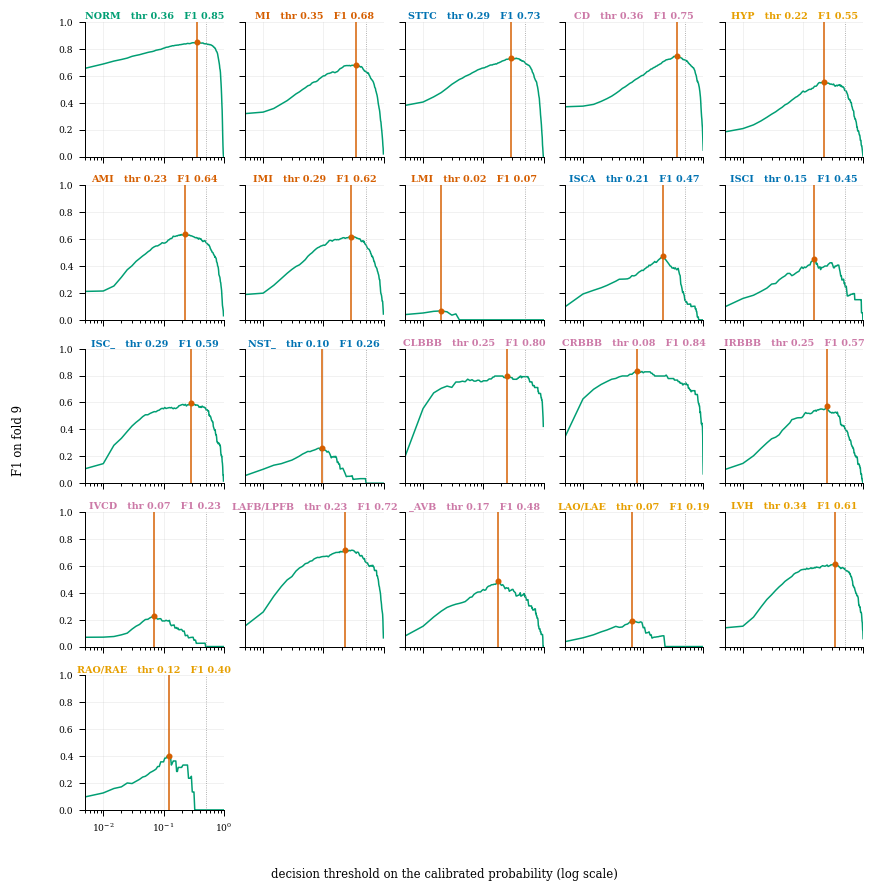

In [11]:
# ---- Figure 2: F1 against the threshold, every reliable label --------------------------------------------------------------
rl = [j for j in range(26) if REL_VAL[j]]; nc = 5; nr = int(math.ceil(len(rl) / nc))
fig, axs = plt.subplots(nr, nc, figsize=(W2, 1.4 * nr + 0.35), sharex=True, sharey=True)
axs = np.atleast_2d(axs).ravel()
for a, j in zip(axs, rl):
    a.plot(GRID, F1V['Chief Resident'][j], color=C_CR, lw=0.9)
    a.axvline(THR['Chief Resident'][j], color='#D55E00', lw=0.9); a.axvline(0.5, color='#999999', lw=0.5, ls=':')
    a.plot([THR['Chief Resident'][j]], [np.nanmax(F1V['Chief Resident'][j])], 'o', color='#D55E00', ms=2.6)
    a.set_xscale('log'); a.set_xlim(0.005, 1); a.set_ylim(0, 1.0)
    a.set_title(f'{LABELS[j]}   thr {THR["Chief Resident"][j]:.2f}   F1 {np.nanmax(F1V["Chief Resident"][j]):.2f}', fontsize=5.8, color=fam_col(LABELS[j]), fontweight='bold', pad=2)
for a in axs[len(rl):]: a.axis('off')
for a in axs[:len(rl)]: a.tick_params(labelsize=5.5)
fig.supxlabel('decision threshold on the calibrated probability (log scale)', fontsize=7, y=0.0); fig.supylabel('F1 on fold 9', fontsize=7, x=0.0)
fig.tight_layout(rect=(0.01, 0.01, 1, 1)); save_fig(fig, 'fig02_threshold_curves')

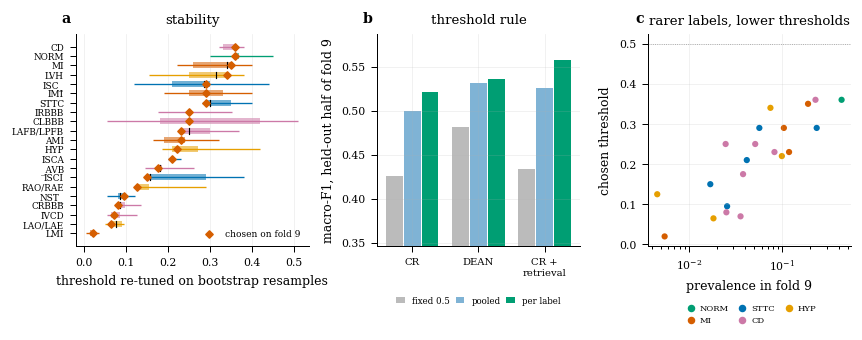

In [12]:
# ---- Figure 3: stability and value of per-label thresholds ----------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(W2, 3.0), gridspec_kw=dict(width_ratios=[1.15, 1, 1]))
ordl = sorted(rl, key=lambda j: THR['Chief Resident'][j]); yy = np.arange(len(ordl))
for y_, j in zip(yy, ordl):
    q = np.nanpercentile(TB[:, j], [5, 25, 50, 75, 95])
    ax[0].hlines(y_, q[0], q[4], color=fam_col(LABELS[j]), lw=0.8); ax[0].barh(y_, q[3] - q[1], left=q[1], height=0.65, color=fam_col(LABELS[j]), alpha=0.55, lw=0); ax[0].plot([q[2]] * 2, [y_ - 0.32, y_ + 0.32], color='black', lw=0.7)
ax[0].scatter([THR['Chief Resident'][j] for j in ordl], yy, marker='D', s=9, color='#D55E00', zorder=5, label='chosen on fold 9')
ax[0].set_yticks(yy); ax[0].set_yticklabels([LABELS[j] for j in ordl], fontsize=5.3); ax[0].set_xlabel('threshold re-tuned on bootstrap resamples'); ax[0].legend(loc='lower right', fontsize=5.4); ax[0].grid(axis='y', alpha=0); ax[0].set_title('stability'); panel(ax[0], 'a')
rules = list(XF_RULES.columns); xs = np.arange(len(XF_RULES)); cols_ = ['#BBBBBB', '#7FB3D5', C_CR]
for m, (r_, c) in enumerate(zip(rules, cols_)):
    ax[1].bar(xs + (m - 1) * 0.27, XF_RULES[r_], 0.25, color=c, label=r_)
ax[1].set_xticks(xs); ax[1].set_xticklabels(['CR', 'DEAN', 'CR +\nretrieval'], fontsize=6); ax[1].set_ylabel('macro-F1, held-out half of fold 9')
ax[1].set_ylim(max(0.0, XF_RULES.values.min() - 0.08), XF_RULES.values.max() + 0.03); ax[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=5.2, columnspacing=0.7, handlelength=1); ax[1].set_title('threshold rule'); panel(ax[1], 'b')
ax[2].scatter(T10['prevalence_val'][REL_VAL], T10['threshold'][REL_VAL], s=14, c=[fam_col(LABELS[j]) for j in rl], lw=0)
ax[2].set_xscale('log'); ax[2].set_xlabel('prevalence in fold 9'); ax[2].set_ylabel('chosen threshold'); ax[2].axhline(0.5, color='#999999', lw=0.5, ls=':'); ax[2].set_title('rarer labels, lower thresholds'); panel(ax[2], 'c')
ax[2].legend(handles=[Line2D([], [], marker='o', ls='', color=c, markersize=3.5, label=k) for k, c in SUPER_COL.items()], ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.24), fontsize=5, handletextpad=0.1, columnspacing=0.6)
fig.tight_layout(); save_fig(fig, 'fig03_threshold_stability')

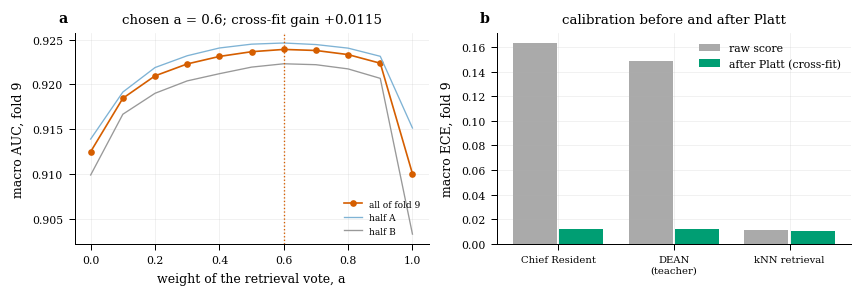

In [13]:
# ---- Figure 4: the mixing weight and the fold-9 calibration -------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(W2, 2.5))
ax[0].plot(ALPHAS, FUS_CURVE, 'o-', ms=3, color=C_FUS, label='all of fold 9')
for h, (c, lab) in zip(FUS_HALF, [('#7FB3D5', 'half A'), ('#999999', 'half B')]): ax[0].plot(ALPHAS, h, '-', color=c, lw=0.8, label=lab)
ax[0].axvline(ALPHA, color=C_FUS, ls=':', lw=0.8); ax[0].set_xlabel('weight of the retrieval vote, a'); ax[0].set_ylabel('macro AUC, fold 9'); ax[0].legend(loc='lower right', ncol=1, fontsize=5.4)
ax[0].set_title(f'chosen a = {ALPHA:g}; cross-fit gain {FUS_XF_GAIN:+.4f}'); panel(ax[0], 'a')
nm = list(ZV); xe = np.arange(len(nm))
ax[1].bar(xe - .2, [np.nanmean(ECE_VA[n][0][REL_VAL]) for n in nm], .38, color='#AAAAAA', label='raw score'); ax[1].bar(xe + .2, [np.nanmean(ECE_VA[n][1][REL_VAL]) for n in nm], .38, color=C_CR, label='after Platt (cross-fit)')
ax[1].set_xticks(xe); ax[1].set_xticklabels([n.replace(' (', '\n(') for n in nm], fontsize=6); ax[1].set_ylabel('macro ECE, fold 9'); ax[1].legend(); ax[1].set_title('calibration before and after Platt'); panel(ax[1], 'b')
fig.tight_layout(); save_fig(fig, 'fig04_mixing_weight_and_calibration')

## 6. Freezing the configuration
Every number the test evaluation will use is written to `frozen_config.json` now, together with the SHA-256 of the files it refers to (the deployed model, the DEAN checkpoint, the index and its metadata). The test fold is not touched before this cell has run, and nothing in the notebook writes to this file again.

In [14]:
def idx_path(which):
    p = os.path.join(IDX_ROOT, f'index_{which}.faiss')
    return p if os.path.exists(p) else p + '.npy'
sysd = lambda n: dict(platt_a=PLATT[n][0].tolist(), platt_b=PLATT[n][1].tolist(), thresholds=THR[n].tolist(), pooled_threshold=POOLED[n])
FROZEN = dict(
    version=1, labels=LABELS, grid=GRID.tolist(), reliable_val=REL_VAL.tolist(),
    systems=dict(chief_resident=sysd('Chief Resident'), dean=sysd('DEAN (teacher)'), knn=dict(sysd('kNN retrieval'), k=int(PCFG['k']), tau=PCFG['tau'], index='trainval'),
                 fusion=dict(alpha=ALPHA, thresholds=THR['CR + retrieval'].tolist(), pooled_threshold=POOLED['CR + retrieval'], curve_val=FUS_CURVE.tolist(), alphas=ALPHAS.tolist())),
    claims_declared=dict(margin_auc=CFG['margin_auc'], margin_f1=CFG['margin_f1'], speed_claim=CFG['speed_claim']),
    cfg={k: v for k, v in CFG.items() if k != 'lat_reps'},
    hashes=dict(deploy=sha256(P_DEPLOY), dean=sha256(find_one('dean_finetuned.pt')), index_trainval=sha256(idx_path('trainval')), index_train=sha256(idx_path('train')),
                prototype_meta=sha256(os.path.join(IDX_ROOT, 'prototype_meta.npz')), prototype_config=sha256(os.path.join(IDX_ROOT, 'prototype_config.json'))))
FZ_PATH = os.path.join(WORK, 'frozen_config.json')
json.dump(FROZEN, open(FZ_PATH, 'w'), indent=1)
FZ_SHA, FZ_TIME = sha256(FZ_PATH), os.path.getmtime(FZ_PATH)
check('configuration frozen before any test access', _TEST_ACCESS['n'] == 0, f'sha256 {FZ_SHA[:16]}...')
check('thresholds lie on the grid and are finite', all(np.isin(np.round(np.array(s['thresholds']), 3), GRID).all() for s in FROZEN['systems'].values() if 'thresholds' in s))
print('frozen:', {k: (v if not isinstance(v, (list, dict)) else '...') for k, v in FROZEN.items()}, '\nfile', FZ_PATH, 'sha256', FZ_SHA)

[ok] configuration frozen before any test access: sha256 4d29fc5460f6f29b...
[ok] thresholds lie on the grid and are finite
frozen: {'version': 1, 'labels': '...', 'grid': '...', 'reliable_val': '...', 'systems': '...', 'claims_declared': '...', 'cfg': '...', 'hashes': '...'} 
file /kaggle/working/frozen_config.json sha256 4d29fc5460f6f29b96fd1135e7b19bd0520baf9f8f28e3ac03f3ae7e57457f72


## 7. The test fold, once
The fold-10 signals go through both networks and the index, the frozen maps turn the scores into probabilities, and **then** the labels are loaded, through the counting function, one time. All results below are computed from the arrays created in this cell.

In [15]:
assert _TEST_ACCESS['n'] == 0 and sha256(FZ_PATH) == FZ_SHA, 'the configuration must be frozen and the test labels untouched'
t0 = time.time()
OUT_TE = forward_all(te_idx, CFG['bs_infer'])
RT_ALL = PL.Retriever(IDX_ROOT, 'trainval')
S_KNN_TE, D_TE, I_TE = RT_ALL.scores(OUT_TE['dean_z'])
S_KNN_TE_TR = RT_TR.scores(OUT_TE['dean_z'])[0]                              # sensitivity only: the index used on fold 9
print(f'fold 10 passed through both networks and the index in {time.time() - t0:.0f} s')
for k, v in OUT_TE.items(): check(f'fold-10 {k} finite', bool(np.isfinite(v).all()), v.shape)
FS = FROZEN['systems']
fzp = lambda k: (np.array(FS[k]['platt_a']), np.array(FS[k]['platt_b']), np.array(FS[k]['thresholds']))
PT, TH = OrderedDict(), OrderedDict()
a_, b_, TH['Chief Resident'] = fzp('chief_resident'); PT['Chief Resident'] = sigmoid(OUT_TE['cr_logits'] * a_ + b_)
a_, b_, TH['DEAN (teacher)'] = fzp('dean'); PT['DEAN (teacher)'] = sigmoid(OUT_TE['dean_logits'] * a_ + b_)
a_, b_, TH['kNN retrieval'] = fzp('knn'); PT['kNN retrieval'] = sigmoid(lg(S_KNN_TE) * a_ + b_); P_KNN_TE_TRIDX = sigmoid(lg(S_KNN_TE_TR) * a_ + b_)
TH['CR + retrieval'] = np.array(FS['fusion']['thresholds']); PT['CR + retrieval'] = fuse(PT['Chief Resident'], PT['kNN retrieval'], FS['fusion']['alpha'])
POOL = OrderedDict([('Chief Resident', FS['chief_resident']['pooled_threshold']), ('DEAN (teacher)', FS['dean']['pooled_threshold']), ('kNN retrieval', FS['knn']['pooled_threshold']), ('CR + retrieval', FS['fusion']['pooled_threshold'])])
np.savez_compressed(os.path.join(WORK, 'test_predictions.npz'), ecg_id=ecg_id[te_idx], labels=np.array(LABELS), cr_logits=OUT_TE['cr_logits'], dean_logits=OUT_TE['dean_logits'], knn_votes=S_KNN_TE,
                    **{'p_' + n.split(' (')[0].replace(' + ', '_plus_').replace(' ', '_').lower(): p for n, p in PT.items()}, thr_cr=TH['Chief Resident'])
np.savez_compressed(os.path.join(WORK, 'test_explanations.npz'), ecg_id=ecg_id[te_idx], neighbour_ecg_id=RT_ALL.ecg_id[I_TE[:, :CFG['k_proto']]], neighbour_similarity=D_TE[:, :CFG['k_proto']],
                    neighbour_labels=RT_ALL.Y[I_TE[:, :CFG['k_proto']]].astype(np.int8))
check('the test fold is not in the index used for the explanations', set(ecg_id[te_idx]).isdisjoint(set(RT_ALL.ecg_id.tolist())))

Y_TE = get_test_labels()                                                      # <- the one and only access to the fold-10 labels
check('fold-10 labels loaded exactly once', _TEST_ACCESS['n'] == 1, _TEST_ACCESS['n'])
check('the frozen configuration was written before the test labels were read', FZ_TIME < _TEST_ACCESS['when'])
check('the frozen file is unchanged', sha256(FZ_PATH) == FZ_SHA)
YB = Y_TE > 0
REL_TE = Y_TE.sum(0) >= CFG['min_pos']; REL_HEAD = REL_VAL & REL_TE; ANY_TE = (Y_TE.sum(0) >= 1) & (Y_TE.sum(0) < NTE)
SCOPE = OrderedDict(all=REL_HEAD, super=REL_HEAD & (np.arange(26) < 5), sub=REL_HEAD & (np.arange(26) >= 5))
SCOPE_ANY = ANY_TE
print(f'fold 10: {NTE} records | labels in the headline averages: {int(REL_HEAD.sum())}/26 ({int(SCOPE["super"].sum())} super, {int(SCOPE["sub"].sum())} sub)')
print('left out (fewer than 10 positives in fold 9 or in fold 10): ' + ', '.join(f'{LABELS[i]} (val {int(Y_va[:, i].sum())}, test {int(Y_TE[:, i].sum())})' for i in np.where(~REL_HEAD)[0]))
check('every superclass is in the headline average', bool(REL_HEAD[:5].all()))

fold 10 passed through both networks and the index in 10 s
[ok] fold-10 cr_logits finite: (2198, 26)
[ok] fold-10 dean_z finite: (2198, 256)
[ok] fold-10 dean_logits finite: (2198, 26)
[ok] the test fold is not in the index used for the explanations
[ok] fold-10 labels loaded exactly once: 1
[ok] the frozen configuration was written before the test labels were read
[ok] the frozen file is unchanged
fold 10: 2198 records | labels in the headline averages: 20/26 (5 super, 15 sub)
left out (fewer than 10 positives in fold 9 or in fold 10): PMI (val 2, test 2), ILBBB (val 7, test 8), WPW (val 7, test 8), RAO/RAE (val 10, test 9), RVH (val 9, test 11), SEHYP (val 3, test 2)
[ok] every superclass is in the headline average


True

### 7.1 Metrics and the paired bootstrap
All systems are scored on the same 1,000 bootstrap resamples of fold-10 records (the thresholds stay frozen; they are not re-tuned per resample). A difference between two systems is the difference of the two macro scores inside each resample, so the interval is a paired one. AUC uses the calibrated probability (the Platt map is monotone, so for a single model it equals the AUC of the raw score).

In [16]:
rng_b = np.random.default_rng(CFG['seed']); BIDX = rng_b.integers(0, NTE, (CFG['n_boot'], NTE))
SYSN = list(PT)
PRED = OrderedDict((n, PT[n] >= TH[n][None]) for n in SYSN)
def f1_from(y, p):
    tp = (y & p).sum(0).astype(float); fp = p.sum(0) - tp; fn = y.sum(0) - tp; den = 2 * tp + fp + fn
    f = np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0); f[y.sum(0) == 0] = np.nan
    return f
def boot_f1(y, p): return np.stack([f1_from(y[ix], p[ix]) for ix in BIDX])
def boot_auc(S): return np.stack([auc_cols(Y_TE[ix], S[ix]) for ix in BIDX])
assert np.allclose(np.nan_to_num(f1_from(YB, PRED['Chief Resident'])), np.nan_to_num(eval_lib.f1_at(Y_TE, PT['Chief Resident'], TH['Chief Resident'])))
assert np.allclose(np.nan_to_num(auc_cols(Y_TE, PT['Chief Resident'])[REL_HEAD]), np.nan_to_num(eval_lib.auc_per_label(Y_TE, PT['Chief Resident'], 1)[REL_HEAD]), atol=1e-9)
t0 = time.time()
A_PT = OrderedDict((n, auc_cols(Y_TE, PT[n])) for n in SYSN); A_BT = OrderedDict((n, boot_auc(PT[n])) for n in SYSN)
F_PT = OrderedDict((n, f1_from(YB, PRED[n])) for n in SYSN); F_BT = OrderedDict((n, boot_f1(YB, PRED[n])) for n in SYSN)
# the other threshold rules, frozen from fold 9, for the Chief Resident
RULE_PRED = OrderedDict([('per label (frozen)', PRED['Chief Resident']), ('pooled', PT['Chief Resident'] >= POOL['Chief Resident']), ('fixed 0.5', PT['Chief Resident'] >= 0.5)])
FR_PT = OrderedDict((k, f1_from(YB, v)) for k, v in RULE_PRED.items()); FR_BT = OrderedDict((k, boot_f1(YB, v)) for k, v in RULE_PRED.items())
print(f'bootstrap done in {time.time() - t0:.0f} s')
pct = lambda v: [float(np.nanmean(v)), float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))]
def macro_pt(P, sc, scope=None): return float(np.nanmean(P[(SCOPE if scope is None else scope)[sc]]))
def macro_bt(B, sc, scope=None): return np.nanmean(B[:, (SCOPE if scope is None else scope)[sc]], 1)
def delta(Ba, Bb, Pa, Pb, sc):
    d = macro_bt(Ba, sc) - macro_bt(Bb, sc)
    return dict(delta=macro_pt(Pa, sc) - macro_pt(Pb, sc), lo=float(np.percentile(d, 2.5)), hi=float(np.percentile(d, 97.5)))
rows = []
for n in SYSN:
    for sc in SCOPE:
        va, vf = macro_bt(A_BT[n], sc), macro_bt(F_BT[n], sc)
        rows.append(dict(system=n, scope=sc, n_labels=int(SCOPE[sc].sum()), macro_auc=macro_pt(A_PT[n], sc), auc_lo=float(np.percentile(va, 2.5)), auc_hi=float(np.percentile(va, 97.5)),
                         macro_f1=macro_pt(F_PT[n], sc), f1_lo=float(np.percentile(vf, 2.5)), f1_hi=float(np.percentile(vf, 97.5))))
MAIN = pd.DataFrame(rows); MAIN.to_csv(os.path.join(TAB_DIR, 'test_main_results.csv'), index=False)
SENS = pd.DataFrame([dict(system=n, macro_auc_any_label=float(np.nanmean(A_PT[n][SCOPE_ANY])), macro_f1_any_label=float(np.nanmean(F_PT[n][SCOPE_ANY])), n_labels=int(SCOPE_ANY.sum())) for n in SYSN])
SENS.to_csv(os.path.join(TAB_DIR, 'test_sensitivity_all_labels.csv'), index=False)
with pd.option_context('display.width', 200):
    print(MAIN[MAIN.scope == 'all'].set_index('system')[['n_labels', 'macro_f1', 'f1_lo', 'f1_hi', 'macro_auc', 'auc_lo', 'auc_hi']].round(4).to_string())
    print(MAIN.pivot(index='system', columns='scope', values='macro_f1').loc[SYSN].round(4).rename(columns=lambda c: 'F1 ' + c).to_string())
    print('sensitivity, every label with at least one test positive:'); print(SENS.round(4).to_string(index=False))

# ---- record-level metrics ----
def agg(y, p):
    tp, fp, fn = (y & p).sum(), p.sum() - (y & p).sum(), y.sum() - (y & p).sum()
    micro = 2 * tp / max(2 * tp + fp + fn, 1)
    tps = (y & p).sum(1).astype(float); den = 2 * tps + (p.sum(1) - tps) + (y.sum(1) - tps)
    samp = np.where(den > 0, 2 * tps / np.maximum(den, 1), 1.0)
    return np.array([micro, samp.mean(), (y == p).all(1).mean(), (y != p).mean()])
REC = pd.DataFrame({n: dict(zip(['micro_f1', 'sample_f1', 'subset_accuracy', 'hamming_loss'], agg(YB, PRED[n]))) for n in SYSN}).T
RECB = {n: np.stack([agg(YB[ix], PRED[n][ix]) for ix in BIDX[:300]]) for n in SYSN}
for j, c in enumerate(REC.columns): REC[c + '_lo'], REC[c + '_hi'] = [np.percentile(RECB[n][:, j], 2.5) for n in SYSN], [np.percentile(RECB[n][:, j], 97.5) for n in SYSN]
REC.to_csv(os.path.join(TAB_DIR, 'test_record_level.csv')); print(REC[['micro_f1', 'sample_f1', 'subset_accuracy', 'hamming_loss']].round(4).to_string())
sup_of = np.array([-1] * 5 + [SUPER.index(FAMILY[l]) for l in SUB])
def violations(pred):
    sub_on = pred[:, 5:]; bad = np.zeros(len(pred), bool)
    for k, l in enumerate(SUB): bad |= sub_on[:, k] & ~pred[:, sup_of[5 + k]]
    return float(bad.mean())
VIOL = {n: violations(PRED[n]) for n in SYSN}; print('records predicting a subclass without its superclass:', {n: round(v, 4) for n, v in VIOL.items()})

bootstrap done in 29 s
                n_labels  macro_f1   f1_lo   f1_hi  macro_auc  auc_lo  auc_hi
system                                                                       
Chief Resident        20    0.5211  0.5031  0.5398     0.9061  0.8944  0.9168
DEAN (teacher)        20    0.5476  0.5293  0.5644     0.9194  0.9091  0.9286
kNN retrieval         20    0.5486  0.5278  0.5669     0.9033  0.8909  0.9154
CR + retrieval        20    0.5534  0.5331  0.5719     0.9145  0.9029  0.9249
scope           F1 all  F1 sub  F1 super
system                                  
Chief Resident  0.5211  0.4659    0.6866
DEAN (teacher)  0.5476  0.4917    0.7151
kNN retrieval   0.5486  0.4944    0.7111
CR + retrieval  0.5534  0.5008    0.7110
sensitivity, every label with at least one test positive:
        system  macro_auc_any_label  macro_f1_any_label  n_labels
Chief Resident               0.8800              0.4217        26
DEAN (teacher)               0.9171              0.4654        26
 kNN re

### 7.2 Per-label results

In [17]:
def per_label(n):
    p, y, s = PRED[n], YB, PT[n]
    tp = (y & p).sum(0); fp = p.sum(0) - tp; fn = y.sum(0) - tp; tn = (~y & ~p).sum(0)
    ap = np.array([average_precision_score(y[:, j], s[:, j]) if 0 < y[:, j].sum() < NTE else np.nan for j in range(26)])
    return pd.DataFrame(dict(label=LABELS, family=['super'] * 5 + [FAMILY[l] for l in SUB], n_test_pos=y.sum(0), n_val_pos=Y_va.sum(0).astype(int), in_headline=REL_HEAD, threshold=TH[n],
                             auc=A_PT[n], auc_lo=np.nanpercentile(A_BT[n], 2.5, 0), auc_hi=np.nanpercentile(A_BT[n], 97.5, 0), ap=ap, f1=F_PT[n], f1_lo=np.nanpercentile(F_BT[n], 2.5, 0), f1_hi=np.nanpercentile(F_BT[n], 97.5, 0),
                             precision=tp / np.maximum(tp + fp, 1), recall=tp / np.maximum(tp + fn, 1), specificity=tn / np.maximum(tn + fp, 1), tp=tp, fp=fp, fn=fn, tn=tn))
PLT = {n: per_label(n) for n in SYSN}
for n in SYSN: PLT[n].to_csv(os.path.join(TAB_DIR, 'test_per_label_' + n.split(' (')[0].replace(' + ', '_plus_').replace(' ', '_').lower() + '.csv'), index=False)
with pd.option_context('display.width', 220, 'display.max_rows', 40):
    print(PLT['Chief Resident'][['label', 'n_test_pos', 'in_headline', 'threshold', 'auc', 'ap', 'f1', 'precision', 'recall']].round(3).to_string(index=False))

    label  n_test_pos  in_headline  threshold   auc    ap    f1  precision  recall
     NORM         954         True      0.360 0.930 0.896 0.836      0.771   0.913
       MI         415         True      0.350 0.899 0.709 0.639      0.639   0.639
     STTC         506         True      0.290 0.922 0.785 0.727      0.661   0.806
       CD         496         True      0.360 0.895 0.777 0.696      0.701   0.692
      HYP         222         True      0.220 0.882 0.570 0.535      0.484   0.599
      AMI         247         True      0.230 0.930 0.674 0.611      0.557   0.676
      IMI         224         True      0.290 0.919 0.643 0.587      0.594   0.580
      LMI          10         True      0.020 0.822 0.059 0.083      0.048   0.300
      PMI           2        False      0.210 0.480 0.001 0.000      0.000   0.000
     ISCA          93         True      0.210 0.916 0.323 0.351      0.302   0.419
     ISCI          40         True      0.150 0.931 0.327 0.345      0.319   0.375
    

## 8. Pre-declared claims
Each claim was fixed in Section 1 (tolerances) and in the introduction, before any fold-10 number existed. A claim is **supported** if its 95 % paired interval lies on the claimed side (for non-inferiority: above minus the tolerance), **contradicted** if it lies entirely on the other side, and **not supported** otherwise. "Not supported" is not "false": the data do not decide.

In [18]:
CL = []
def add_claim(cid, text, d, margin=0.0, noninf=False, metric=''):
    if noninf: v = 'supported' if d['lo'] > -margin else ('contradicted' if d['hi'] < -margin else 'not supported')
    else: v = 'supported' if d['lo'] > 0 else ('contradicted' if d['hi'] < 0 else 'not supported')
    CL.append(dict(id=cid, claim=text, metric=metric, margin=margin if noninf else 0.0, delta=d['delta'], lo=d['lo'], hi=d['hi'], verdict=v))
CR_, DE_, FU_ = 'Chief Resident', 'DEAN (teacher)', 'CR + retrieval'
add_claim('C1', 'Chief Resident is non-inferior to DEAN in macro-AUC', delta(A_BT[CR_], A_BT[DE_], A_PT[CR_], A_PT[DE_], 'all'), CFG['margin_auc'], True, 'macro AUC')
add_claim('C2', 'Chief Resident is non-inferior to DEAN in macro-F1', delta(F_BT[CR_], F_BT[DE_], F_PT[CR_], F_PT[DE_], 'all'), CFG['margin_f1'], True, 'macro F1')
add_claim('C3', 'Chief Resident has a higher macro-AUC than DEAN', delta(A_BT[CR_], A_BT[DE_], A_PT[CR_], A_PT[DE_], 'all'), 0, False, 'macro AUC')
add_claim('C4', 'adding the retrieval vote raises the macro-AUC of the Chief Resident', delta(A_BT[FU_], A_BT[CR_], A_PT[FU_], A_PT[CR_], 'all'), 0, False, 'macro AUC')
add_claim('C5', 'adding the retrieval vote raises the macro-F1 of the Chief Resident', delta(F_BT[FU_], F_BT[CR_], F_PT[FU_], F_PT[CR_], 'all'), 0, False, 'macro F1')
add_claim('C6', 'per-label thresholds from fold 9 beat a fixed 0.5 (Chief Resident, macro-F1)', delta(FR_BT['per label (frozen)'], FR_BT['fixed 0.5'], FR_PT['per label (frozen)'], FR_PT['fixed 0.5'], 'all'), 0, False, 'macro F1')
add_claim('C7', 'per-label thresholds from fold 9 beat one pooled threshold (Chief Resident, macro-F1)', delta(FR_BT['per label (frozen)'], FR_BT['pooled'], FR_PT['per label (frozen)'], FR_PT['pooled'], 'all'), 0, False, 'macro F1')
add_claim('C8', 'Chief Resident + retrieval is non-inferior to DEAN in macro-AUC', delta(A_BT[FU_], A_BT[DE_], A_PT[FU_], A_PT[DE_], 'all'), CFG['margin_auc'], True, 'macro AUC')
CLAIMS = pd.DataFrame(CL)
with pd.option_context('display.width', 240, 'display.max_colwidth', 90):
    print(CLAIMS[['id', 'claim', 'delta', 'lo', 'hi', 'margin', 'verdict']].round(4).to_string(index=False))

id                                                                                 claim   delta      lo      hi  margin       verdict
C1                                   Chief Resident is non-inferior to DEAN in macro-AUC -0.0133 -0.0195 -0.0069    0.01 not supported
C2                                    Chief Resident is non-inferior to DEAN in macro-F1 -0.0265 -0.0397 -0.0124    0.02 not supported
C3                                       Chief Resident has a higher macro-AUC than DEAN -0.0133 -0.0195 -0.0069    0.00  contradicted
C4                  adding the retrieval vote raises the macro-AUC of the Chief Resident  0.0084  0.0037  0.0129    0.00     supported
C5                   adding the retrieval vote raises the macro-F1 of the Chief Resident  0.0323  0.0204  0.0441    0.00     supported
C6          per-label thresholds from fold 9 beat a fixed 0.5 (Chief Resident, macro-F1)  0.0690  0.0546  0.0846    0.00     supported
C7 per-label thresholds from fold 9 beat one pooled thr

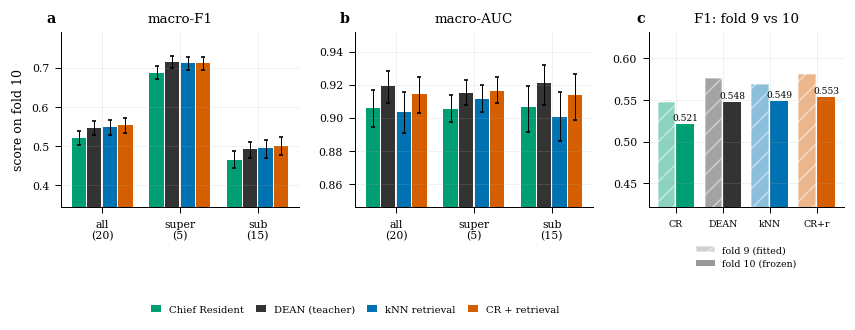

In [19]:
# ---- Figure 5: headline results --------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(W2, 2.7), gridspec_kw=dict(width_ratios=[1.1, 1.1, 0.9]))
xs = np.arange(3); wd = 0.2
for k, (met, lo_, hi_, ttl) in enumerate((('macro_f1', 'f1_lo', 'f1_hi', 'macro-F1'), ('macro_auc', 'auc_lo', 'auc_hi', 'macro-AUC'))):
    for m, n in enumerate(SYSN):
        d_ = MAIN[MAIN.system == n].set_index('scope').loc[list(SCOPE)]
        ax[k].bar(xs + (m - 1.5) * wd, d_[met], wd * 0.92, color=SYS_COL[n], label=n, yerr=[d_[met] - d_[lo_], d_[hi_] - d_[met]], error_kw=dict(lw=0.6, capsize=1.2))
    ax[k].set_xticks(xs); ax[k].set_xticklabels([f'{s}\n({int(SCOPE[s].sum())})' for s in SCOPE]); ax[k].set_title(ttl); panel(ax[k], 'ab'[k])
lo_f = MAIN['f1_lo'].min(); ax[0].set_ylim(max(0, lo_f - 0.1), min(1.0, MAIN['f1_hi'].max() + 0.06)); ax[1].set_ylim(max(0.5, MAIN['auc_lo'].min() - 0.04), min(1.0, MAIN['auc_hi'].max() + 0.02))
ax[0].set_ylabel('score on fold 10')
fig.legend(*ax[0].get_legend_handles_labels(), loc='lower center', ncol=4, fontsize=6, columnspacing=1.2, handlelength=1, bbox_to_anchor=(0.42, -0.01))
vt = pd.DataFrame({n: dict(val=VAL_F1.loc[n, 'macro_f1_tuned'], test=MAIN[(MAIN.system == n) & (MAIN.scope == 'all')].macro_f1.iloc[0]) for n in SYSN}).T
xx = np.arange(len(SYSN))
ax[2].bar(xx - 0.2, vt['val'], 0.38, color=[SYS_COL[n] for n in SYSN], alpha=0.45, hatch='//', edgecolor='white', label='fold 9 (thresholds fitted here)')
ax[2].bar(xx + 0.2, vt['test'], 0.38, color=[SYS_COL[n] for n in SYSN], label='fold 10 (frozen)')
for i, n in enumerate(SYSN): ax[2].text(i + 0.2, vt['test'].iloc[i] + 0.004, f'{vt["test"].iloc[i]:.3f}', ha='center', fontsize=5.4)
ax[2].set_xticks(xx); ax[2].set_xticklabels(['CR', 'DEAN', 'kNN', 'CR+r'], fontsize=5.6); ax[2].set_ylim(max(0, vt.values.min() - 0.1), vt.values.max() + 0.05); ax[2].set_title('F1: fold 9 vs 10'); panel(ax[2], 'c')
ax[2].legend(handles=[mpl.patches.Patch(fc='#999999', alpha=0.45, hatch='//', ec='white', label='fold 9 (fitted)'), mpl.patches.Patch(fc='#999999', label='fold 10 (frozen)')], loc='upper center', bbox_to_anchor=(0.5, -0.17), fontsize=5.6, ncol=1)
fig.tight_layout(rect=(0, 0.07, 1, 1)); save_fig(fig, 'fig05_headline_results')

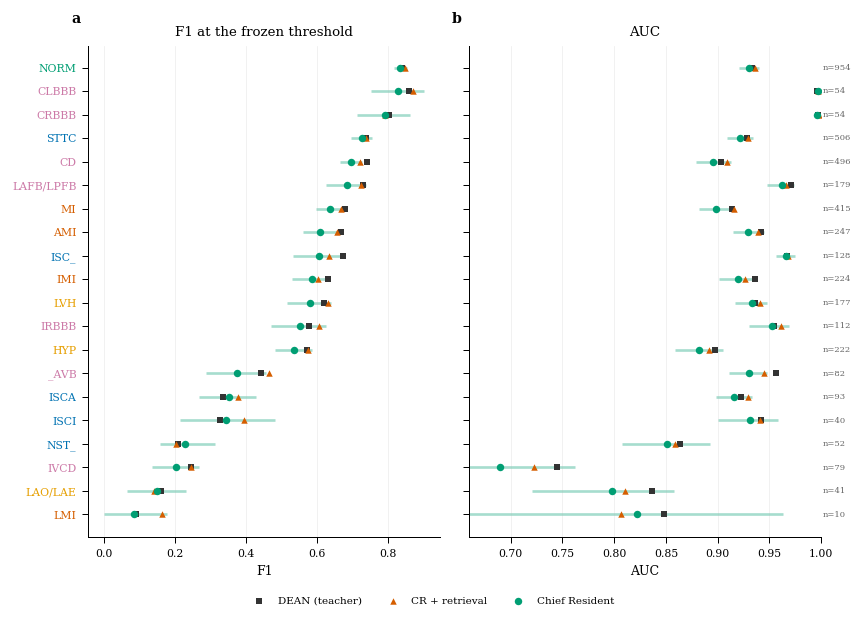

In [20]:
# ---- Figure 6: per label, F1 and AUC ---------------------------------------------------------------------------------------------
od = [j for j in np.argsort(-np.nan_to_num(F_PT[CR_], nan=-1)) if REL_HEAD[j]]; yy = np.arange(len(od))[::-1]
fig, ax = plt.subplots(1, 2, figsize=(W2, 0.2 * len(od) + 1.1), sharey=True)
for k, (P_, B_, ttl, xl) in enumerate(((F_PT, F_BT, 'F1 at the frozen threshold', 'F1'), (A_PT, A_BT, 'AUC', 'AUC'))):
    lo_, hi_ = np.nanpercentile(B_[CR_], 2.5, 0), np.nanpercentile(B_[CR_], 97.5, 0)
    ax[k].hlines(yy, lo_[od], hi_[od], color=C_CR, lw=1.6, alpha=0.35, zorder=1)
    for n, mk, s_ in ((DE_, 's', 14), (FU_, '^', 15), (CR_, 'o', 20)):
        ax[k].scatter(P_[n][od], yy, marker=mk, s=s_, color=SYS_COL[n], zorder=3 if n == CR_ else 2, label=n, lw=0)
    ax[k].set_yticks(yy); ax[k].set_yticklabels([LABELS[j] for j in od]); ax[k].grid(axis='y', alpha=0); ax[k].set_xlabel(xl); ax[k].set_title(ttl); panel(ax[k], 'ab'[k])
ax[1].set_xlim(max(0.5, np.nanmin([A_PT[n][od].min() for n in (CR_, DE_, FU_)]) - 0.03), 1.0)
for t, j in zip(ax[0].get_yticklabels(), od): t.set_color(fam_col(LABELS[j]))
for y_, j in zip(yy, od): ax[1].text(1.003, y_, f'n={int(Y_TE[:, j].sum())}', fontsize=5, va='center', color='#666666', transform=ax[1].get_yaxis_transform())
fig.legend(*ax[1].get_legend_handles_labels(), loc='lower center', ncol=3, fontsize=6.2, bbox_to_anchor=(0.5, -0.005))
fig.tight_layout(rect=(0, 0.035, 1, 1)); save_fig(fig, 'fig06_per_label')

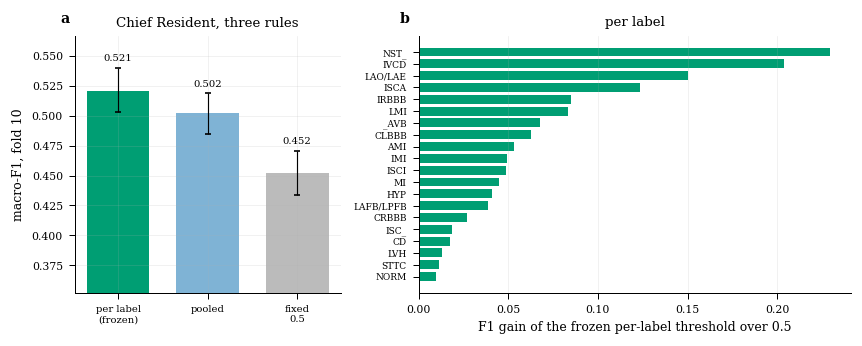

In [21]:
# ---- Figure 7: threshold rules on the test fold (all frozen) -------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(W2, 2.9), gridspec_kw=dict(width_ratios=[0.8, 1.3]))
rn = list(RULE_PRED); cols_ = [C_CR, '#7FB3D5', '#BBBBBB']
for i, (r_, c) in enumerate(zip(rn, cols_)):
    v_ = macro_bt(FR_BT[r_], 'all'); pt_ = macro_pt(FR_PT[r_], 'all')
    ax[0].bar(i, pt_, 0.7, color=c, yerr=[[pt_ - np.percentile(v_, 2.5)], [np.percentile(v_, 97.5) - pt_]], error_kw=dict(lw=0.7, capsize=2)); ax[0].text(i, np.percentile(v_, 97.5) + 0.006, f'{pt_:.3f}', ha='center', fontsize=6)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(['per label\n(frozen)', 'pooled', 'fixed\n0.5'], fontsize=6); ax[0].set_ylabel('macro-F1, fold 10'); ax[0].set_ylim(max(0, min(macro_pt(FR_PT[r], 'all') for r in rn) - 0.1), None); ax[0].set_title('Chief Resident, three rules'); panel(ax[0], 'a')
gain = np.nan_to_num(FR_PT['per label (frozen)'] - FR_PT['fixed 0.5']); od2 = [j for j in np.argsort(gain) if REL_HEAD[j]]
ax[1].barh(np.arange(len(od2)), gain[od2], color=[C_CR if gain[j] >= 0 else '#D55E00' for j in od2], height=0.75)
ax[1].set_yticks(np.arange(len(od2))); ax[1].set_yticklabels([LABELS[j] for j in od2], fontsize=5.4); ax[1].axvline(0, color='black', lw=0.6); ax[1].grid(axis='y', alpha=0)
ax[1].set_xlabel('F1 gain of the frozen per-label threshold over 0.5'); ax[1].set_title('per label'); panel(ax[1], 'b')
fig.tight_layout(); save_fig(fig, 'fig07_threshold_rules_test')

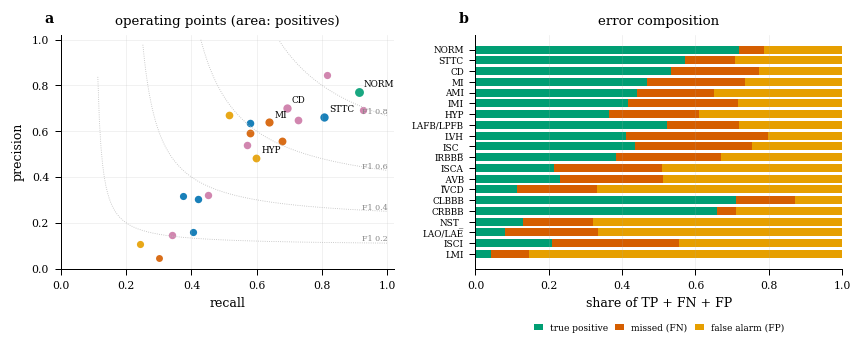

In [22]:
# ---- Figure 8: operating points and error composition (frozen thresholds, Chief Resident) -------------------------------------
T = PLT[CR_]; m_ = REL_HEAD
fig, ax = plt.subplots(1, 2, figsize=(W2, 3.0), gridspec_kw=dict(width_ratios=[1, 1.1]))
gx = np.linspace(0.02, 1, 200)
for f_ in (0.2, 0.4, 0.6, 0.8):
    rr = f_ * gx / (2 * gx - f_); ok = rr > 0; rr = np.where(ok & (rr <= 1.0), rr, np.nan); ax[0].plot(gx, rr, color='#BBBBBB', lw=0.5, ls=':'); ax[0].text(1.0, f_ / (2 - f_), f'F1 {f_}', fontsize=4.8, color='#888888', ha='right', va='bottom')
for j in np.where(m_)[0]:
    ax[0].scatter(T['recall'][j], T['precision'][j], s=16 + 0.4 * np.sqrt(T['n_test_pos'][j]), color=fam_col(LABELS[j]), lw=0, alpha=0.9)
    if j < 5: ax[0].annotate(LABELS[j], (T['recall'][j], T['precision'][j]), fontsize=5.3, xytext=(3, 3), textcoords='offset points')
ax[0].set_xlim(0, 1.02); ax[0].set_ylim(0, 1.02); ax[0].set_xlabel('recall'); ax[0].set_ylabel('precision'); ax[0].set_title('operating points (area: positives)'); panel(ax[0], 'a')
ordc = [j for j in np.argsort(-T['n_test_pos'].values) if m_[j]]; tot = (T['tp'] + T['fp'] + T['fn']).values.astype(float)
left = np.zeros(len(ordc)); yy = np.arange(len(ordc))[::-1]
for nm_, col_ in (('tp', C_CR), ('fn', '#D55E00'), ('fp', '#E69F00')):
    v_ = np.array([T[nm_][j] / max(tot[j], 1) for j in ordc]); ax[1].barh(yy, v_, left=left, color=col_, height=0.75, label={'tp': 'true positive', 'fn': 'missed (FN)', 'fp': 'false alarm (FP)'}[nm_]); left += v_
ax[1].set_yticks(yy); ax[1].set_yticklabels([LABELS[j] for j in ordc], fontsize=5.3); ax[1].set_xlabel('share of TP + FN + FP'); ax[1].grid(axis='y', alpha=0); ax[1].set_xlim(0, 1)
ax[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=5.4, columnspacing=0.8, handlelength=1); ax[1].set_title('error composition'); panel(ax[1], 'b')
fig.tight_layout(); save_fig(fig, 'fig08_operating_points')

## 9. From fold 9 to fold 10, curves, calibration, error structure
Figure 9 compares each label's fold-9 and fold-10 numbers: points far below the diagonal are labels whose fold-9 F1 was an over-estimate (typically rare ones, where the threshold was tuned on a few positives). The right panel isolates the threshold: the same predictions scored with the frozen thresholds and, as a **diagnostic only** that is never reported as a result, with thresholds re-fitted on fold 10, which bounds what a perfect threshold could add. Figures 10 to 12 give the curves, the calibration of the frozen Platt maps, and which labels the model confuses.

diagnostic: macro-F1 0.5211 with the frozen thresholds vs 0.5446 if they were fitted on fold 10 itself (the most a perfect threshold could add: +0.0235)


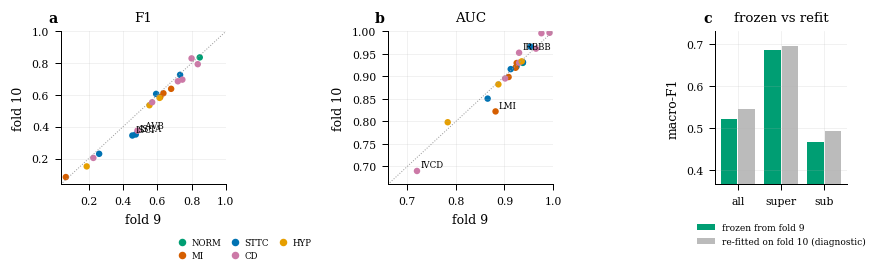

In [23]:
F1_VA_CR = eval_lib.f1_at(Y_va, PV[CR_], THR[CR_]); A_VA_CR = AUC_CR_VA
THR_OR = tune(Y_TE, PT[CR_], REL_HEAD)[0]                                    # DIAGNOSTIC ONLY: thresholds fitted on the test fold
F1_OR = eval_lib.f1_at(Y_TE, PT[CR_], THR_OR)
GAP_F1 = {sc: macro_pt(F1_OR, sc) - macro_pt(F_PT[CR_], sc) for sc in SCOPE}
print(f'diagnostic: macro-F1 {macro_pt(F_PT[CR_], "all"):.4f} with the frozen thresholds vs {macro_pt(F1_OR, "all"):.4f} if they were fitted on fold 10 itself (the most a perfect threshold could add: {GAP_F1["all"]:+.4f})')
fig, ax = plt.subplots(1, 3, figsize=(W2, 2.55), gridspec_kw=dict(width_ratios=[1, 1, 0.8]))
for k, (v_, t_, ttl) in enumerate(((F1_VA_CR, F_PT[CR_], 'F1'), (A_VA_CR, A_PT[CR_], 'AUC'))):
    m_ = REL_HEAD
    ax[k].scatter(v_[m_], t_[m_], s=15, c=[fam_col(LABELS[j]) for j in np.where(m_)[0]], lw=0)
    lim = [min(np.nanmin(v_[m_]), np.nanmin(t_[m_])) - 0.03, 1.0]; ax[k].plot(lim, lim, color='#999999', lw=0.6, ls=':'); ax[k].set_xlim(lim); ax[k].set_ylim(lim)
    dd_ = np.where(m_)[0][np.argsort(-np.abs(np.nan_to_num(t_[m_] - v_[m_])))[:3]]
    for j in dd_: ax[k].annotate(LABELS[j], (v_[j], t_[j]), fontsize=5.2, xytext=(2, 2), textcoords='offset points')
    ax[k].set_xlabel('fold 9'); ax[k].set_ylabel('fold 10'); ax[k].set_title(ttl); panel(ax[k], 'ab'[k])
ax[0].legend(handles=[Line2D([], [], marker='o', ls='', color=c, markersize=3.5, label=k_) for k_, c in SUPER_COL.items()], ncol=3, loc='upper center', bbox_to_anchor=(1.1, -0.3), fontsize=5.2, handletextpad=0.1, columnspacing=0.6)
sc_ = list(SCOPE); xx = np.arange(3)
ax[2].bar(xx - 0.2, [macro_pt(F_PT[CR_], s) for s in sc_], 0.38, color=C_CR, label='frozen from fold 9'); ax[2].bar(xx + 0.2, [macro_pt(F1_OR, s) for s in sc_], 0.38, color='#BBBBBB', label='re-fitted on fold 10 (diagnostic)')
ax[2].set_xticks(xx); ax[2].set_xticklabels(sc_); ax[2].set_ylabel('macro-F1'); ax[2].set_ylim(max(0, min(macro_pt(F_PT[CR_], s) for s in sc_) - 0.1), None); ax[2].set_title('frozen vs refit'); panel(ax[2], 'c')
ax[2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), fontsize=5.4, ncol=1)
fig.tight_layout(); save_fig(fig, 'fig09_fold9_to_fold10')

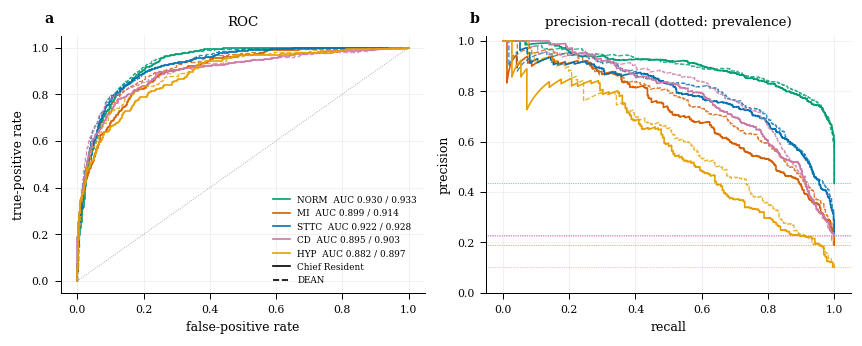

In [24]:
# ---- Figure 10: ROC and precision-recall of the superclasses -----------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(W2, 2.9))
for j in range(5):
    for n, ls in ((CR_, '-'), (DE_, '--')):
        fpr, tpr, _ = roc_curve(Y_TE[:, j], PT[n][:, j]); ax[0].plot(fpr, tpr, ls=ls, color=SUPER_COL[SUPER[j]], lw=1.0 if n == CR_ else 0.8, alpha=1 if n == CR_ else 0.8)
        pr, rc, _ = precision_recall_curve(Y_TE[:, j], PT[n][:, j]); ax[1].plot(rc, pr, ls=ls, color=SUPER_COL[SUPER[j]], lw=1.0 if n == CR_ else 0.8, alpha=1 if n == CR_ else 0.8)
    ax[1].axhline(Y_TE[:, j].mean(), color=SUPER_COL[SUPER[j]], lw=0.4, ls=':')
ax[0].plot([0, 1], [0, 1], color='#999999', lw=0.5, ls=':'); ax[0].set_xlabel('false-positive rate'); ax[0].set_ylabel('true-positive rate'); ax[0].set_title('ROC'); panel(ax[0], 'a')
ax[1].set_xlabel('recall'); ax[1].set_ylabel('precision'); ax[1].set_title('precision-recall (dotted: prevalence)'); panel(ax[1], 'b'); ax[1].set_ylim(0, 1.02)
hl = [Line2D([], [], color=SUPER_COL[s], label=f'{s}  AUC {A_PT[CR_][i]:.3f} / {A_PT[DE_][i]:.3f}') for i, s in enumerate(SUPER)] + [Line2D([], [], color='k', ls='-', label='Chief Resident'), Line2D([], [], color='k', ls='--', label='DEAN')]
ax[0].legend(handles=hl, loc='lower right', fontsize=5.3)
fig.tight_layout(); save_fig(fig, 'fig10_roc_pr_superclasses')

{'Chief Resident': {'raw': 0.1509, 'frozen': 0.0105}, 'DEAN (teacher)': {'raw': 0.1402, 'frozen': 0.0083}, 'kNN retrieval': {'raw': 0.0103, 'frozen': 0.007}, 'CR + retrieval': {'raw': nan, 'frozen': 0.0081}}


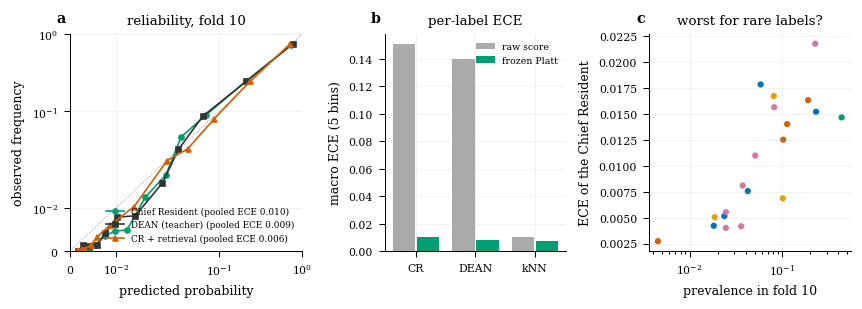

In [25]:
# ---- Figure 11: calibration of the frozen maps on fold 10 ------------------------------------------------------------------------
rawp = {CR_: sigmoid(OUT_TE['cr_logits']), DE_: sigmoid(OUT_TE['dean_logits']), 'kNN retrieval': S_KNN_TE}
ece_l = lambda y, p: reliability(y, p, 5)[2]
ECE_TE = {n: dict(raw=float(np.nanmean([ece_l(YB[:, j].astype(float), rawp[n][:, j]) for j in np.where(REL_HEAD)[0]])), frozen=float(np.nanmean([ece_l(YB[:, j].astype(float), PT[n][:, j]) for j in np.where(REL_HEAD)[0]]))) for n in rawp}
ECE_TE[FU_] = dict(raw=np.nan, frozen=float(np.nanmean([ece_l(YB[:, j].astype(float), PT[FU_][:, j]) for j in np.where(REL_HEAD)[0]])))
print({n: {k: round(v, 4) for k, v in d.items()} for n, d in ECE_TE.items()})
fig, ax = plt.subplots(1, 3, figsize=(W2, 2.6), gridspec_kw=dict(width_ratios=[1.15, 0.9, 1]))
ax[0].plot([0, 1], [0, 1], color='#999999', lw=0.6, ls=':'); yv_ = YB[:, REL_HEAD].ravel().astype(float)
for n, mk in ((CR_, 'o'), (DE_, 's'), (FU_, '^')):
    conf, acc, ece = reliability(yv_, PT[n][:, REL_HEAD].ravel(), 12); ax[0].plot(conf, acc, marker=mk, ms=3, color=SYS_COL[n], label=f'{n} (pooled ECE {ece:.3f})')
ax[0].set_xscale('symlog', linthresh=0.02); ax[0].set_yscale('symlog', linthresh=0.02); ax[0].set_xlim(0, 1); ax[0].set_ylim(0, 1); ax[0].set_xlabel('predicted probability'); ax[0].set_ylabel('observed frequency')
ax[0].legend(loc='lower right', fontsize=5.3); ax[0].set_title('reliability, fold 10'); panel(ax[0], 'a')
nn_ = [CR_, DE_, 'kNN retrieval']; xe = np.arange(3)
ax[1].bar(xe - 0.2, [ECE_TE[n]['raw'] for n in nn_], 0.38, color='#AAAAAA', label='raw score'); ax[1].bar(xe + 0.2, [ECE_TE[n]['frozen'] for n in nn_], 0.38, color=C_CR, label='frozen Platt')
ax[1].set_xticks(xe); ax[1].set_xticklabels(['CR', 'DEAN', 'kNN'], fontsize=6.5); ax[1].set_ylabel('macro ECE (5 bins)'); ax[1].legend(fontsize=5.6); ax[1].set_title('per-label ECE'); panel(ax[1], 'b')
ecl = np.array([ece_l(YB[:, j].astype(float), PT[CR_][:, j]) if REL_HEAD[j] else np.nan for j in range(26)])
ax[2].scatter(Y_TE.mean(0)[REL_HEAD], ecl[REL_HEAD], s=14, c=[fam_col(LABELS[j]) for j in np.where(REL_HEAD)[0]], lw=0); ax[2].set_xscale('log'); ax[2].set_xlabel('prevalence in fold 10'); ax[2].set_ylabel('ECE of the Chief Resident'); ax[2].set_title('worst for rare labels?'); panel(ax[2], 'c')
fig.tight_layout(); save_fig(fig, 'fig11_calibration_fold10')

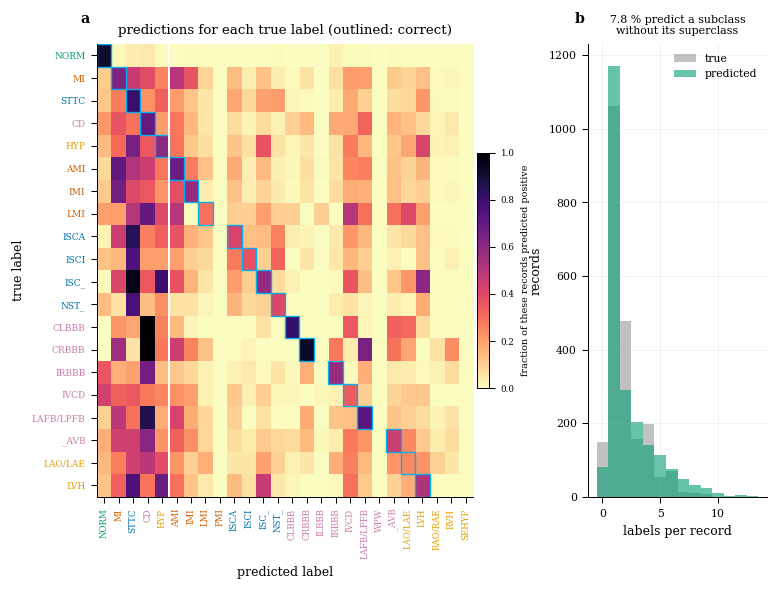

In [26]:
# ---- Figure 12: which labels are confused, and how many labels per record ----------------------------------------------------
rows_ = [j for j in range(26) if REL_HEAD[j]]
CO = np.stack([PRED[CR_][YB[:, i]].mean(0) for i in rows_])
fig = plt.figure(figsize=(W2, 0.17 * len(rows_) + 1.5)); gs = fig.add_gridspec(1, 2, width_ratios=[2.2, 1], wspace=0.35)
ax0, ax1 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
im = ax0.imshow(CO, aspect='auto', cmap='magma_r', vmin=0, vmax=1)
ax0.set_xticks(range(26)); ax0.set_xticklabels(LABELS, rotation=90, fontsize=5.2); ax0.set_yticks(range(len(rows_))); ax0.set_yticklabels([LABELS[i] for i in rows_], fontsize=5.4); ax0.grid(False)
for t, i in zip(ax0.get_yticklabels(), rows_): t.set_color(fam_col(LABELS[i]))
for t, l in zip(ax0.get_xticklabels(), LABELS): t.set_color(fam_col(l))
for r, i in enumerate(rows_): ax0.add_patch(plt.Rectangle((i - .5, r - .5), 1, 1, fill=False, ec='#00B0F0', lw=0.8))
ax0.axvline(4.5, color='white', lw=1.2); cb = fig.colorbar(im, ax=ax0, fraction=0.03, pad=0.01); cb.set_label('fraction of these records predicted positive', fontsize=5.8); cb.ax.tick_params(labelsize=5.2)
ax0.set_xlabel('predicted label'); ax0.set_ylabel('true label'); ax0.set_title('predictions for each true label (outlined: correct)'); panel(ax0, 'a')
nt_, np_ = YB.sum(1), PRED[CR_].sum(1); mx = int(max(nt_.max(), np_.max())) + 1
ax1.hist(nt_, bins=np.arange(mx + 1) - 0.5, alpha=0.6, color='#999999', label='true'); ax1.hist(np_, bins=np.arange(mx + 1) - 0.5, alpha=0.6, color=C_CR, label='predicted')
ax1.set_xlabel('labels per record'); ax1.set_ylabel('records'); ax1.legend(); ax1.set_title(f'{VIOL[CR_] * 100:.1f} % predict a subclass\nwithout its superclass', fontsize=6.6); panel(ax1, 'b')
save_fig(fig, 'fig12_error_structure')

## 10. The prototype lookup as an explanation
In the deployed pipeline the index does not decide anything: it returns the nearest training ECGs as the explanation of the prediction (Step 11, item 4). Three questions decide whether that explanation is worth showing, all answered on fold 10 with `index_trainval`.

1. Do the retrieved ECGs share the record's diagnoses (precision at rank k, lift over the label's prevalence)?
2. Do they support the model's own predictions: for a label the Chief Resident predicts, does the fraction of the five retrieved ECGs carrying that label separate correct predictions from false ones?
3. Does a low similarity to the nearest prototype flag records the model gets wrong?

top-1 prototype: label Jaccard 0.558 (random ECG 0.222), identical label set 0.452; median lift@10 over headline labels 5.3
precision@10 of the superclasses: NORM 0.82 (prev 0.43), MI 0.52 (prev 0.19), STTC 0.62 (prev 0.23), CD 0.65 (prev 0.22), HYP 0.43 (prev 0.10)


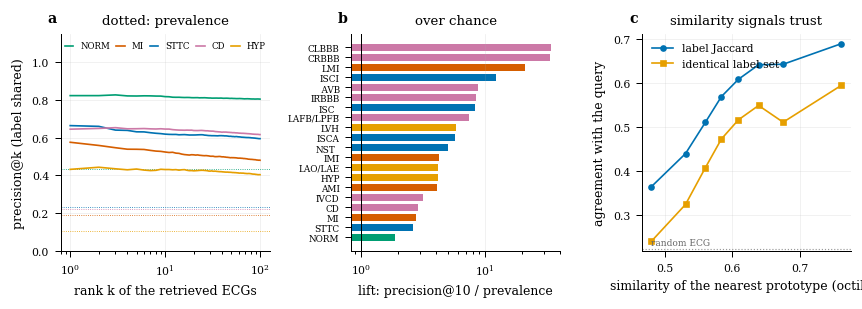

In [27]:
KR = min(100, I_TE.shape[1]); GT = RT_ALL.Y[I_TE[:, :KR]]                    # (N, K, 26) labels of the retrieved training ECGs
PREV_IDX = RT_ALL.Y.mean(0)
PK = np.full((26, KR), np.nan)
for j in range(26):
    pos = YB[:, j]
    if pos.sum() >= 1: PK[j] = np.cumsum(GT[pos, :, j].mean(0)) / np.arange(1, KR + 1)
K10 = min(10, KR); LIFT = PK[:, K10 - 1] / np.maximum(PREV_IDX, 1e-9)
jac = lambda a, b: np.minimum(a, b).sum(1) / np.maximum(np.maximum(a, b).sum(1), 1)
J1 = jac(Y_TE, RT_ALL.Y[I_TE[:, 0]]); rr_ = np.random.default_rng(1); J_CH = float(jac(Y_TE, RT_ALL.Y[rr_.integers(0, len(RT_ALL.Y), NTE)]).mean())
print(f'top-1 prototype: label Jaccard {J1.mean():.3f} (random ECG {J_CH:.3f}), identical label set {(Y_TE == RT_ALL.Y[I_TE[:, 0]]).all(1).mean():.3f}; median lift@{K10} over headline labels {np.nanmedian(LIFT[REL_HEAD]):.1f}')
print('precision@' + str(K10) + ' of the superclasses: ' + ', '.join(f'{LABELS[j]} {PK[j, K10 - 1]:.2f} (prev {PREV_IDX[j]:.2f})' for j in range(5)))
sim1 = D_TE[:, 0]; qb = np.array_split(np.argsort(sim1), 8)
fig, ax = plt.subplots(1, 3, figsize=(W2, 2.6))
for j in range(5):
    ax[0].plot(np.arange(1, KR + 1), PK[j], color=SUPER_COL[LABELS[j]], label=LABELS[j]); ax[0].axhline(PREV_IDX[j], color=SUPER_COL[LABELS[j]], lw=0.5, ls=':')
ax[0].set_xscale('log'); ax[0].set_xlabel('rank k of the retrieved ECGs'); ax[0].set_ylabel('precision@k (label shared)'); ax[0].legend(ncol=5, loc='upper center', fontsize=5.2, columnspacing=0.7, handlelength=1); ax[0].set_ylim(0, 1.15); ax[0].set_title('dotted: prevalence'); panel(ax[0], 'a')
ordr = [i for i in np.argsort(-LIFT) if REL_HEAD[i] and np.isfinite(LIFT[i])]
ax[1].barh(np.arange(len(ordr))[::-1], LIFT[ordr], color=[fam_col(LABELS[i]) for i in ordr], height=0.75); ax[1].set_xscale('log')
ax[1].set_yticks(np.arange(len(ordr))[::-1]); ax[1].set_yticklabels([LABELS[i] for i in ordr], fontsize=5.3); ax[1].axvline(1, color='black', lw=0.6); ax[1].grid(axis='y', alpha=0)
ax[1].set_xlabel(f'lift: precision@{K10} / prevalence'); ax[1].set_title('over chance'); panel(ax[1], 'b')
mb = [sim1[b].mean() for b in qb]; EX1 = (Y_TE == RT_ALL.Y[I_TE[:, 0]]).all(1)
ax[2].plot(mb, [J1[b].mean() for b in qb], 'o-', color=C_KNN, ms=3, label='label Jaccard'); ax[2].plot(mb, [EX1[b].mean() for b in qb], 's-', color='#E69F00', ms=3, label='identical label set')
ax[2].axhline(J_CH, color='#999999', ls=':', lw=0.7); ax[2].text(mb[0], J_CH + 0.01, 'random ECG', fontsize=5.4, color='#666666')
ax[2].set_xlabel('similarity of the nearest prototype (octiles)'); ax[2].set_ylabel('agreement with the query'); ax[2].legend(loc='upper left'); ax[2].set_title('similarity signals trust'); panel(ax[2], 'c')
fig.tight_layout(); save_fig(fig, 'fig13_prototype_quality')

4901 predicted (record, label) pairs on headline labels, 0.596 correct | AUC of prototype support for correct vs false: 0.784 [0.770, 0.800] | AUC of the model probability itself: 0.800 [0.787, 0.814]
 prototypes_with_label  n_predictions  precision
                     0            602      0.191
                     1            656      0.335
                     2            691      0.447
                     3            719      0.606
                     4            880      0.733
                     5           1353      0.885
AUC of nearest-prototype similarity for "every label right": 0.585


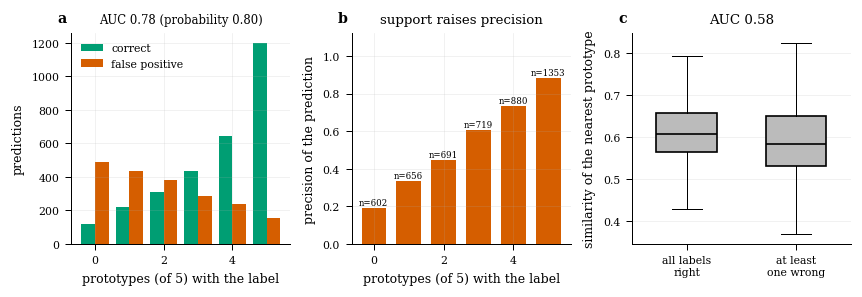

In [28]:
# ---- support of a prediction by its prototypes -----------------------------------------------------------------------------------
from sklearn.metrics import roc_auc_score
ks = CFG['k_proto']; SUP = RT_ALL.Y[I_TE[:, :ks]].mean(1)                     # (N, 26) fraction of the five prototypes carrying each label
mk_ = PRED[CR_] & REL_HEAD[None]; ri, cj = np.where(mk_); is_tp = YB[ri, cj]; sup_v = SUP[ri, cj]; prob_v = PT[CR_][ri, cj]
def wauc(y, s, w):
    return roc_auc_score(y, s, sample_weight=w) if 0 < y[w > 0].sum() < (w > 0).sum() else np.nan
AUC_SUP, AUC_PROB = wauc(is_tp, sup_v, np.ones(len(ri))), wauc(is_tp, prob_v, np.ones(len(ri)))
bs_sup, bs_prob = [], []
for ix in BIDX[:300]:
    w = np.bincount(ix, minlength=NTE)[ri].astype(float); bs_sup.append(wauc(is_tp, sup_v, w)); bs_prob.append(wauc(is_tp, prob_v, w))
bs_sup, bs_prob = np.array(bs_sup), np.array(bs_prob)
add_claim('C9', 'the prototype support of a predicted label separates correct from false positive predictions (AUC > 0.5)', dict(delta=AUC_SUP - 0.5, lo=float(np.nanpercentile(bs_sup, 2.5)) - 0.5, hi=float(np.nanpercentile(bs_sup, 97.5)) - 0.5), 0, False, 'AUC - 0.5')
CLAIMS = pd.DataFrame(CL)
nsup = np.rint(sup_v * ks).astype(int)
SUPT = pd.DataFrame([dict(prototypes_with_label=s, n_predictions=int((nsup == s).sum()), precision=float(is_tp[nsup == s].mean()) if (nsup == s).any() else np.nan) for s in range(ks + 1)])
SUPT.to_csv(os.path.join(TAB_DIR, 'prototype_support_precision.csv'), index=False)
exact = (YB == PRED[CR_]).all(1); AUC_SIM = roc_auc_score(exact, sim1) if 0 < exact.sum() < NTE else np.nan
print(f'{len(ri)} predicted (record, label) pairs on headline labels, {is_tp.mean():.3f} correct | AUC of prototype support for correct vs false: {AUC_SUP:.3f} [{np.nanpercentile(bs_sup, 2.5):.3f}, {np.nanpercentile(bs_sup, 97.5):.3f}] | AUC of the model probability itself: {AUC_PROB:.3f} [{np.nanpercentile(bs_prob, 2.5):.3f}, {np.nanpercentile(bs_prob, 97.5):.3f}]')
print(SUPT.round(3).to_string(index=False)); print(f'AUC of nearest-prototype similarity for "every label right": {AUC_SIM:.3f}')
fig, ax = plt.subplots(1, 3, figsize=(W2, 2.5))
w_ = np.ones(len(nsup)) / max(len(nsup), 1)
ax[0].hist([nsup[is_tp], nsup[~is_tp]], bins=np.arange(ks + 2) - 0.5, color=[C_CR, '#D55E00'], label=['correct', 'false positive'], density=False)
ax[0].set_xlabel(f'prototypes (of {ks}) with the label'); ax[0].set_ylabel('predictions'); ax[0].legend(); ax[0].set_title(f'AUC {AUC_SUP:.2f} (probability {AUC_PROB:.2f})', fontsize=7); panel(ax[0], 'a')
ax[1].bar(SUPT['prototypes_with_label'], SUPT['precision'], color=C_FUS, width=0.7)
for s, p, n in zip(SUPT['prototypes_with_label'], SUPT['precision'], SUPT['n_predictions']): ax[1].text(s, (0 if np.isnan(p) else p) + 0.015, f'n={n}', ha='center', fontsize=5.2)
ax[1].set_xlabel(f'prototypes (of {ks}) with the label'); ax[1].set_ylabel('precision of the prediction'); ax[1].set_ylim(0, 1.12); ax[1].set_title('support raises precision'); panel(ax[1], 'b')
ax[2].boxplot([sim1[exact], sim1[~exact]], widths=0.55, patch_artist=True, showfliers=False, medianprops=dict(color='black'),
              boxprops=dict(facecolor='#BBBBBB'), whiskerprops=dict(lw=0.6), capprops=dict(lw=0.6))
ax[2].set_xticks([1, 2]); ax[2].set_xticklabels(['all labels\nright', 'at least\none wrong']); ax[2].set_ylabel('similarity of the nearest prototype'); ax[2].set_title(f'AUC {AUC_SIM:.2f}'); ax[2].grid(axis='x', alpha=0); panel(ax[2], 'c')
fig.tight_layout(); save_fig(fig, 'fig14_prototype_support')

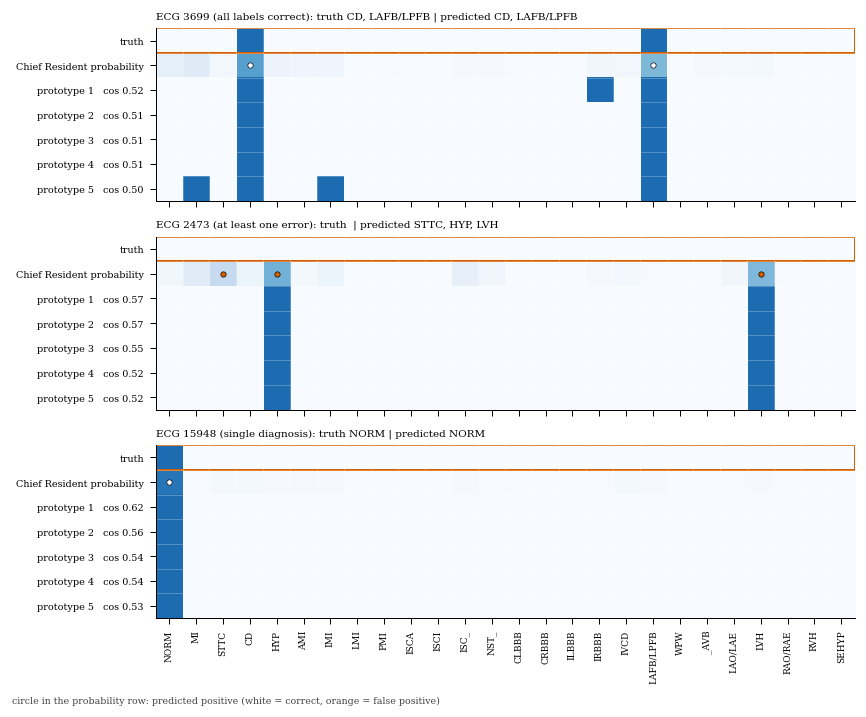

In [29]:
# ---- Figure 15: three explanations as the user would see them ---------------------------------------------------------------------
rq = np.random.default_rng(11)
cands = [np.where(exact & (YB.sum(1) >= 2))[0], np.where(~exact)[0], np.where(YB.sum(1) == 1)[0]]
picks = [int(rq.choice(c)) if len(c) else i for i, c in enumerate(cands)]
tt = ['all labels correct', 'at least one error', 'single diagnosis']
fig, axs = plt.subplots(3, 1, figsize=(W2, 5.9), sharex=True)
for a, q, t_ in zip(axs, picks, tt):
    M = np.vstack([YB[q].astype(float)[None], PT[CR_][q][None], RT_ALL.Y[I_TE[q, :ks]]])
    a.imshow(M, aspect='auto', cmap='Blues', vmin=0, vmax=1.3); a.grid(False)
    a.set_yticks(range(ks + 2)); a.set_yticklabels(['truth', 'Chief Resident probability'] + [f'prototype {r + 1}   cos {D_TE[q, r]:.2f}' for r in range(ks)], fontsize=5.8)
    a.set_xticks(np.arange(-.5, 26, 1), minor=True); a.set_yticks(np.arange(-.5, ks + 2, 1), minor=True); a.grid(which='minor', color='white', lw=0.6); a.tick_params(which='minor', length=0)
    for j in np.where(PRED[CR_][q])[0]: a.plot(j, 1, marker='o', ms=3.2, color='#D55E00' if not YB[q, j] else 'white', mec='black', mew=0.4)
    a.add_patch(plt.Rectangle((-.5, -.5), 26, 1, fill=False, ec='#D55E00', lw=1.2))
    a.set_title(f'ECG {int(ecg_id[te_idx][q])} ({t_}): truth {", ".join(LABELS[j] for j in np.where(YB[q])[0])} | predicted {", ".join(LABELS[j] for j in np.where(PRED[CR_][q])[0]) or "none"}', fontsize=6.2, loc='left')
axs[-1].set_xticks(range(26)); axs[-1].set_xticklabels(LABELS, rotation=90, fontsize=5.4)
fig.text(0.01, 0.005, 'circle in the probability row: predicted positive (white = correct, orange = false positive)', fontsize=5.6, color='#444444')
fig.tight_layout(rect=(0, 0.015, 1, 1)); save_fig(fig, 'fig15_explanations')

## 11. Does the retrieval vote add accuracy?
This is the secondary system. Its mixing weight and thresholds were frozen on fold 9 (Section 6) and the vote of fold-10 records comes from `index_trainval`, which is 12 % larger than the `index_train` that fold 9 used; the last line repeats the evaluation with `index_train` for fold 10 to show that this difference does not drive the result.

macro AUC of the Chief Resident 0.9061 -> with retrieval 0.9145 (index_trainval) / 0.9148 (index_train) | a = 0.6


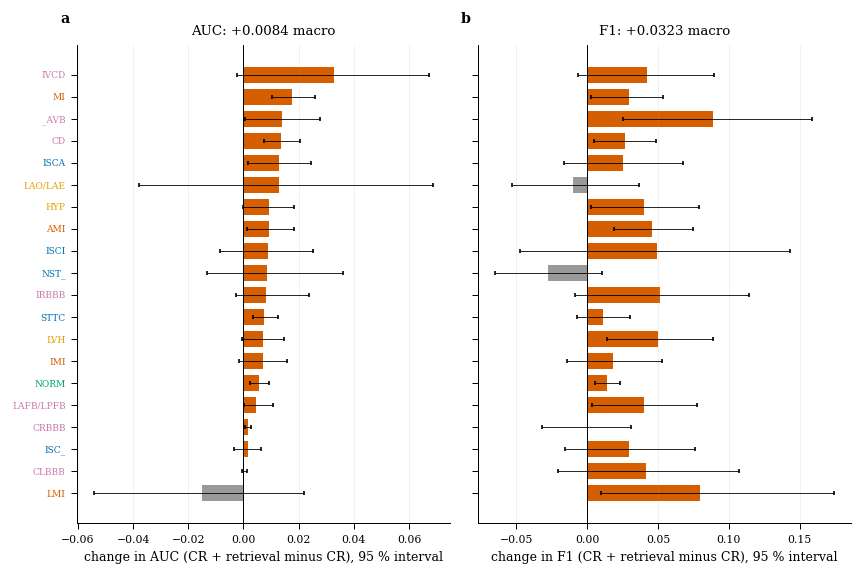

In [30]:
dA = A_BT[FU_] - A_BT[CR_]; dF = F_BT[FU_] - F_BT[CR_]
P_FUS_TR = fuse(PT[CR_], P_KNN_TE_TRIDX, FS['fusion']['alpha']); A_FUS_TR = auc_cols(Y_TE, P_FUS_TR)
print(f'macro AUC of the Chief Resident {macro_pt(A_PT[CR_], "all"):.4f} -> with retrieval {macro_pt(A_PT[FU_], "all"):.4f} (index_trainval) / {float(np.nanmean(A_FUS_TR[REL_HEAD])):.4f} (index_train) | a = {FS["fusion"]["alpha"]}')
od3 = [j for j in np.argsort(np.nan_to_num(A_PT[FU_] - A_PT[CR_])) if REL_HEAD[j]]; yy = np.arange(len(od3))
fig, ax = plt.subplots(1, 2, figsize=(W2, 0.19 * len(od3) + 1.0), sharey=True)
for k, (P_, B_, xl) in enumerate(((A_PT, dA, 'change in AUC'), (F_PT, dF, 'change in F1'))):
    d_ = np.nan_to_num(P_[FU_] - P_[CR_]); lo_, hi_ = np.nanpercentile(B_, 2.5, 0), np.nanpercentile(B_, 97.5, 0)
    ax[k].barh(yy, d_[od3], color=[C_FUS if d_[j] >= 0 else '#999999' for j in od3], height=0.72, xerr=[d_[od3] - lo_[od3], hi_[od3] - d_[od3]], error_kw=dict(lw=0.5, capsize=1))
    ax[k].axvline(0, color='black', lw=0.6); ax[k].set_xlabel(xl + ' (CR + retrieval minus CR), 95 % interval'); ax[k].grid(axis='y', alpha=0); panel(ax[k], 'ab'[k])
ax[0].set_yticks(yy); ax[0].set_yticklabels([LABELS[j] for j in od3], fontsize=5.4)
for t, j in zip(ax[0].get_yticklabels(), od3): t.set_color(fam_col(LABELS[j]))
ax[0].set_title(f'AUC: {macro_pt(A_PT[FU_], "all") - macro_pt(A_PT[CR_], "all"):+.4f} macro'); ax[1].set_title(f'F1: {macro_pt(F_PT[FU_], "all") - macro_pt(F_PT[CR_], "all"):+.4f} macro')
fig.tight_layout(); save_fig(fig, 'fig16_retrieval_fusion')

## 12. Latency: core model and end to end
**Core model** is the deployed Chief Resident alone (normalised signal in, 26 logits out); DEAN is timed the same way for reference. **End to end** is the Step-11 pipeline for one ECG: normalisation, Chief Resident, Platt probabilities and thresholds, then DEAN embedding, transform, exact search of the 19,601-vector index and assembly of the five prototype ECGs. The index is built over DEAN embeddings, so the explanation costs a DEAN forward pass; this is the honest price of the prototype lookup and is reported separately from the core model.

Timing protocol: the library scan (not the faster training-time one), warm-up calls discarded, `perf_counter` with a device synchronisation on both sides on the GPU, the median and the 95th percentile of repeated calls. CPU numbers are given for one thread (a single-core device) and for all threads. Absolute values depend on the machine (printed below); the ratios between models on the same machine are the transferable result.

In [31]:
use_scan(False)
N_THR0 = torch.get_num_threads()
HW = dict(cpu=platform.processor() or platform.machine(), cpu_count=os.cpu_count(), threads_default=N_THR0, gpu=(torch.cuda.get_device_name(0) if dev.type == 'cuda' else None))
print('hardware:', HW)
def sync(d):
    if d.type == 'cuda': torch.cuda.synchronize()
def time_fn(fn, warm, reps, d):
    for _ in range(warm): fn()
    sync(d); ts = []
    for _ in range(reps):
        sync(d); t = time.perf_counter(); fn(); sync(d); ts.append(1e3 * (time.perf_counter() - t))
    return np.array(ts)
CR_CPU, DEAN_CPU = copy.deepcopy(CR).cpu().eval(), copy.deepcopy(DEAN).cpu().eval()
HEAD_CPU = {k: v.cpu() for k, v in HEAD.items()}
def dean_core(m, head, x, d, fp16):
    with (torch.autocast('cuda', dtype=torch.float16) if fp16 else nullcontext()):
        z = m(x).float().mean(1)
    return ((z.float() - head['mu']) / head['sd']) @ head['fc.weight'].T + head['fc.bias']
def cr_core(m, x, d, fp16):
    with (torch.autocast('cuda', dtype=torch.float16) if fp16 else nullcontext()):
        return m(x)
CONFIGS = [('cpu, 1 thread', 'cpu', False, 1), ('cpu, all threads', 'cpu', False, None)]
if dev.type == 'cuda': CONFIGS += [('gpu, fp32', 'cuda', False, None), ('gpu, fp16', 'cuda', True, None)]
LAT, RAW_LAT = [], {}
for cname, dn, fp16, nth in CONFIGS:
    d = torch.device(dn); torch.set_num_threads(nth or N_THR0)
    mc, md, hd = (CR_CPU, DEAN_CPU, HEAD_CPU) if dn == 'cpu' else (CR, DEAN, HEAD)
    for bs in CFG['lat_batches']:
        x = prep(te_idx[np.arange(bs) % NTE]).to(d)
        for mname, fn in (('Chief Resident', lambda: cr_core(mc, x, d, fp16)), ('DEAN (teacher)', lambda: dean_core(md, hd, x, d, fp16))):
            if dn == 'cpu' and mname.startswith('DEAN') and bs > CFG['lat_dean_cpu_max_bs']: continue
            with torch.inference_mode():
                ts = time_fn(fn, CFG['lat_warm'][bs], CFG['lat_reps'][bs], d)
            RAW_LAT[(cname, mname, bs)] = ts
            LAT.append(dict(config=cname, model=mname, batch=bs, median_ms=float(np.median(ts)), p95_ms=float(np.percentile(ts, 95)), per_record_ms=float(np.median(ts)) / bs, records_per_s=1e3 * bs / float(np.median(ts)), reps=len(ts)))
torch.set_num_threads(N_THR0)
LAT = pd.DataFrame(LAT); LAT.to_csv(os.path.join(TAB_DIR, 'latency_core.csv'), index=False)
with pd.option_context('display.width', 200): print(LAT.round(3).to_string(index=False))
SPEED = {}
for cname, *_ in CONFIGS:
    for bs in CFG['lat_batches']:
        a_, b_ = RAW_LAT.get((cname, 'DEAN (teacher)', bs)), RAW_LAT.get((cname, 'Chief Resident', bs))
        if a_ is None or b_ is None: continue
        rg = np.random.default_rng(0); rat = np.array([np.median(rg.choice(a_, len(a_))) / np.median(rg.choice(b_, len(b_))) for _ in range(500)])
        SPEED[(cname, bs)] = dict(ratio=float(np.median(a_) / np.median(b_)), lo=float(np.percentile(rat, 2.5)), hi=float(np.percentile(rat, 97.5)))
print({f'{k[0]} bs{k[1]}': round(v['ratio'], 1) for k, v in SPEED.items()})
sp = SPEED[('cpu, 1 thread', 1)]
add_claim('C10', f'the Chief Resident is at least {CFG["speed_claim"]:g} times faster than DEAN (core model, one record, one CPU thread)', dict(delta=sp['ratio'] - CFG['speed_claim'], lo=sp['lo'] - CFG['speed_claim'], hi=sp['hi'] - CFG['speed_claim']), 0, False, 'speed-up minus tolerance')
CLAIMS = pd.DataFrame(CL)

hardware: {'cpu': 'x86_64', 'cpu_count': 4, 'threads_default': 2, 'gpu': 'Tesla T4'}
          config          model  batch  median_ms  p95_ms  per_record_ms  records_per_s  reps
   cpu, 1 thread Chief Resident      1      6.523   6.882          6.523        153.302   100
   cpu, 1 thread DEAN (teacher)      1     73.751  77.804         73.751         13.559   100
   cpu, 1 thread Chief Resident      8     29.512  31.428          3.689        271.077    30
   cpu, 1 thread DEAN (teacher)      8    841.172 876.999        105.147          9.511    30
   cpu, 1 thread Chief Resident     64    621.258 636.108          9.707        103.017    10
cpu, all threads Chief Resident      1      6.597   7.549          6.597        151.593   100
cpu, all threads DEAN (teacher)      1     72.478  75.896         72.478         13.797   100
cpu, all threads Chief Resident      8     20.666  21.866          2.583        387.108    30
cpu, all threads DEAN (teacher)      8    238.312 246.339         29.

In [32]:
# ---- the deployment pipeline: equal to the batch evaluation, then timed end to end ----------------------------------------------------
PATHS = dict(deploy=P_DEPLOY, dean=find_one('dean_finetuned.pt'), frozen=FZ_PATH, index_root=IDX_ROOT)
nchk = min(64, NTE)
pipe = hidmamba_infer.HiDMambaPipeline(PATHS, device=dev.type, which='trainval', k_proto=CFG['k_proto'])
res = pipe.predict(np.ascontiguousarray(sig[te_idx[:nchk]]).astype(np.float32), explain=True, fuse=True)
p_pipe = np.array([[r['probabilities'][l] for l in LABELS] for r in res]); pf_pipe = np.array([[r['fused_probabilities'][l] for l in LABELS] for r in res])
sim_pipe = np.array([[q['similarity'] for q in r['prototypes']] for r in res])
check('pipeline probabilities equal the batch evaluation (Chief Resident)', np.abs(p_pipe - PT[CR_][:nchk]).max() < 5e-3, f'max |diff| {np.abs(p_pipe - PT[CR_][:nchk]).max():.2e}')
check('pipeline fused probabilities equal the batch evaluation', np.abs(pf_pipe - PT[FU_][:nchk]).max() < 1e-2, f'max |diff| {np.abs(pf_pipe - PT[FU_][:nchk]).max():.2e}')
check('pipeline prototype similarities equal the batch evaluation', np.abs(sim_pipe - D_TE[:nchk, :CFG['k_proto']]).max() < 1e-2, f'max |diff| {np.abs(sim_pipe - D_TE[:nchk, :CFG["k_proto"]]).max():.2e}')
lab_pipe = np.array([[l in r['labels'] for l in LABELS] for r in res])
check('pipeline labels equal the thresholded batch predictions (>= 99 % of entries)', float((lab_pipe == PRED[CR_][:nchk]).mean()) >= 0.99, f'{(lab_pipe == PRED[CR_][:nchk]).mean():.4f}')
check('pipeline returns the requested number of prototypes with ECG ids from the index', all(len(r['prototypes']) == CFG['k_proto'] for r in res) and all(q['ecg_id'] in set(RT_ALL.ecg_id.tolist()) for r in res[:5] for q in r['prototypes']))
del pipe
if dev.type == 'cuda': torch.cuda.empty_cache()

E2E_CONF = [('cpu, 1 thread', 'cpu', 1), ('cpu, all threads', 'cpu', None)] + ([('gpu', 'cuda', None)] if dev.type == 'cuda' else [])
E2E, E2E_STAGES = [], {}
for cname, dn, nth in E2E_CONF:
    torch.set_num_threads(nth or N_THR0)
    pp = hidmamba_infer.HiDMambaPipeline(PATHS, device=dn, which='trainval', k_proto=CFG['k_proto'])
    recs = [np.ascontiguousarray(sig[te_idx[i % NTE]]).astype(np.float32) for i in range(CFG['e2e_n'] + 5)]
    for r in recs[:5]: pp.predict(r, explain=True)
    st, tot, core = [], [], []
    for r in recs[5:]:
        tm = {}; t = time.perf_counter(); pp.predict(r, explain=True, timings=tm); tot.append(1e3 * (time.perf_counter() - t)); st.append(tm)
    for r in recs[5:5 + max(20, CFG['e2e_n'] // 2)]:
        t = time.perf_counter(); pp.predict(r, explain=False); core.append(1e3 * (time.perf_counter() - t))
    keys = ['preprocess', 'chief_resident', 'calibrate', 'dean_embedding', 'retrieval', 'assemble']
    E2E_STAGES[cname] = {k: np.array([s.get(k, 0.0) for s in st]) for k in keys}
    E2E.append(dict(config=cname, core_median_ms=float(np.median(core)), core_p95_ms=float(np.percentile(core, 95)), e2e_median_ms=float(np.median(tot)), e2e_p95_ms=float(np.percentile(tot, 95)), e2e_p99_ms=float(np.percentile(tot, 99)),
                    **{k + '_ms': float(np.median(v)) for k, v in E2E_STAGES[cname].items()}, n=len(tot)))
    E2E_STAGES[cname]['total'] = np.array(tot)
    del pp
    if dn == 'cuda': torch.cuda.empty_cache()
torch.set_num_threads(N_THR0)
E2E = pd.DataFrame(E2E); E2E.to_csv(os.path.join(TAB_DIR, 'latency_end_to_end.csv'), index=False)
with pd.option_context('display.width', 220): print(E2E.round(2).to_string(index=False))
use_scan(True)
check('end-to-end latency is larger than core latency (the explanation has a cost)', bool((E2E['e2e_median_ms'] > E2E['core_median_ms']).all()))

[ok] pipeline probabilities equal the batch evaluation (Chief Resident): max |diff| 1.78e-07
[ok] pipeline fused probabilities equal the batch evaluation: max |diff| 5.99e-03
[ok] pipeline prototype similarities equal the batch evaluation: max |diff| 1.63e-04
[ok] pipeline labels equal the thresholded batch predictions (>= 99 % of entries): 1.0000
[ok] pipeline returns the requested number of prototypes with ECG ids from the index
          config  core_median_ms  core_p95_ms  e2e_median_ms  e2e_p95_ms  e2e_p99_ms  preprocess_ms  chief_resident_ms  calibrate_ms  dean_embedding_ms  retrieval_ms  assemble_ms   n
   cpu, 1 thread            7.78         8.04          93.48       96.82       99.00           0.15               8.05          0.05              83.18          1.96         0.08 100
cpu, all threads            8.45         8.86          95.95       99.86      106.35           0.16               8.46          0.05              84.74          2.30         0.08 100
             gpu

True

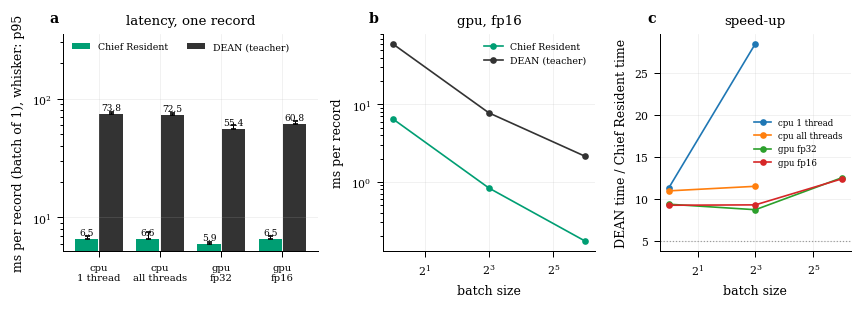

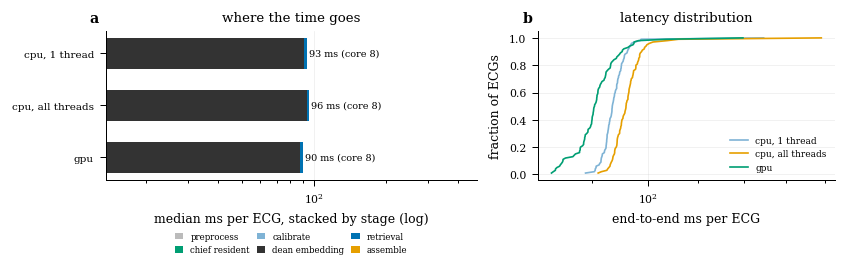

In [33]:
# ---- Figures 17-19: latency and efficiency ------------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(W2, 2.6), gridspec_kw=dict(width_ratios=[1.2, 1, 0.9]))
cn = [c[0] for c in CONFIGS]; xs = np.arange(len(cn))
for m_, (mn, off) in enumerate((('Chief Resident', -0.2), ('DEAN (teacher)', 0.2))):
    v1 = [RAW_LAT[(c, mn, 1)] for c in cn]; med = [np.median(v) for v in v1]; p95 = [np.percentile(v, 95) for v in v1]
    ax[0].bar(xs + off, med, 0.38, color=C_CR if m_ == 0 else C_DEAN, label=mn, yerr=[np.zeros(len(med)), np.array(p95) - np.array(med)], error_kw=dict(lw=0.6, capsize=1.5))
    for x_, v_ in zip(xs + off, med): ax[0].text(x_, v_ * 1.08, f'{v_:.1f}', ha='center', fontsize=5.4)
ax[0].set_yscale('log'); ax[0].set_ylim(None, ax[0].get_ylim()[1] * 4); ax[0].set_xticks(xs); ax[0].set_xticklabels([c.replace(', ', '\n') for c in cn], fontsize=6); ax[0].set_ylabel('ms per record (batch of 1), whisker: p95'); ax[0].legend(fontsize=5.6, loc='upper left', ncol=2); ax[0].set_title('latency, one record'); panel(ax[0], 'a')
bc = cn[-1] if dev.type == 'cuda' else cn[1]
for mn, c in (('Chief Resident', C_CR), ('DEAN (teacher)', C_DEAN)):
    sub_ = LAT[(LAT.config == bc) & (LAT.model == mn)].sort_values('batch'); ax[1].plot(sub_['batch'], sub_['per_record_ms'], 'o-', ms=3, color=c, label=mn)
ax[1].set_xscale('log', base=2); ax[1].set_yscale('log'); ax[1].set_xlabel('batch size'); ax[1].set_ylabel('ms per record'); ax[1].set_title(bc); ax[1].legend(fontsize=5.6); panel(ax[1], 'b')
spd = [(c, b, v) for (c, b), v in SPEED.items()]
for c_i, c in enumerate(cn):
    xs_ = [b for (cc, b, v) in spd if cc == c]; ys_ = [v['ratio'] for (cc, b, v) in spd if cc == c]; ax[2].plot(xs_, ys_, 'o-', ms=3, label=c.replace(', ', ' '))
ax[2].axhline(CFG['speed_claim'], color='#999999', ls=':', lw=0.7); ax[2].set_xscale('log', base=2); ax[2].set_xlabel('batch size'); ax[2].set_ylabel('DEAN time / Chief Resident time'); ax[2].legend(fontsize=5.2); ax[2].set_title('speed-up'); panel(ax[2], 'c')
fig.tight_layout(); save_fig(fig, 'fig17_core_latency')

keys = ['preprocess', 'chief_resident', 'calibrate', 'dean_embedding', 'retrieval', 'assemble']
SC = dict(zip(keys, ['#BBBBBB', C_CR, '#7FB3D5', C_DEAN, C_KNN, '#E69F00']))
fig, ax = plt.subplots(1, 2, figsize=(W2, 2.5), gridspec_kw=dict(width_ratios=[1.25, 1]))
yy = np.arange(len(E2E))[::-1]; left = np.zeros(len(E2E))
for k in keys:
    v_ = E2E[k + '_ms'].values; ax[0].barh(yy, v_, left=left, color=SC[k], label=k.replace('_', ' '), height=0.6); left += v_
for y_, (_, r) in zip(yy, E2E.iterrows()): ax[0].text(left[len(E2E) - 1 - y_] * 1.02, y_, f'{r["e2e_median_ms"]:.0f} ms (core {r["core_median_ms"]:.0f})', va='center', fontsize=5.8)
ax[0].set_yticks(yy); ax[0].set_yticklabels(E2E['config'], fontsize=6.2); ax[0].set_xscale('log'); ax[0].set_xlim(left.min() * 0.15, left.max() * 5)
ax[0].set_xlabel('median ms per ECG, stacked by stage (log)'); ax[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=3, fontsize=5.2, columnspacing=0.8, handlelength=1); ax[0].grid(axis='y', alpha=0); ax[0].set_title('where the time goes'); panel(ax[0], 'a')
for c_, cname in zip(['#7FB3D5', '#E69F00', '#009E73'], [e[0] for e in E2E_CONF]):
    v_ = np.sort(E2E_STAGES[cname]['total']); ax[1].plot(v_, np.arange(1, len(v_) + 1) / len(v_), color=c_, label=cname)
ax[1].set_xscale('log'); ax[1].set_xlabel('end-to-end ms per ECG'); ax[1].set_ylabel('fraction of ECGs'); ax[1].legend(fontsize=5.4); ax[1].set_title('latency distribution'); panel(ax[1], 'b')
fig.tight_layout(); save_fig(fig, 'fig18_end_to_end_latency')

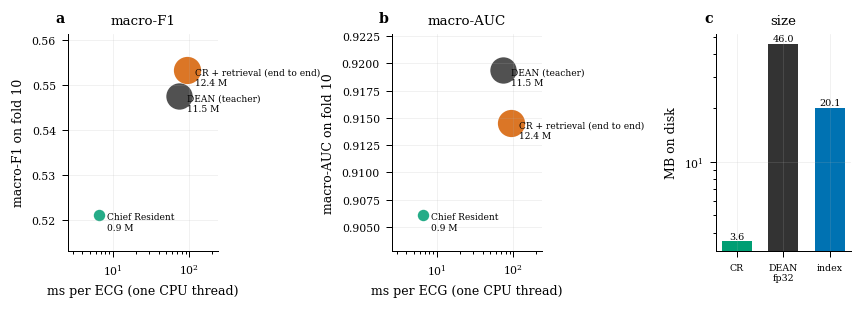

In [34]:
cfg_ref = 'cpu, 1 thread'; l_cr = float(LAT[(LAT.config == cfg_ref) & (LAT.model == 'Chief Resident') & (LAT.batch == 1)].median_ms.iloc[0]); l_de = float(LAT[(LAT.config == cfg_ref) & (LAT.model == 'DEAN (teacher)') & (LAT.batch == 1)].median_ms.iloc[0])
l_e2e = float(E2E[E2E.config == cfg_ref].e2e_median_ms.iloc[0])
pts = [('Chief Resident', l_cr, N_PARAMS_CR, C_CR), ('DEAN (teacher)', l_de, N_PARAMS_DEAN, C_DEAN), ('CR + retrieval\n(end to end)', l_e2e, N_PARAMS_CR + N_PARAMS_DEAN, C_FUS)]
fig, ax = plt.subplots(1, 3, figsize=(W2, 2.6), gridspec_kw=dict(width_ratios=[1, 1, 0.9]))
for k, (met, ttl, yl) in enumerate((('macro_f1', 'macro-F1', 'macro-F1 on fold 10'), ('macro_auc', 'macro-AUC', 'macro-AUC on fold 10'))):
    for (nm, l_, np_, c), sysname in zip(pts, [CR_, DE_, FU_]):
        v_ = MAIN[(MAIN.system == sysname) & (MAIN.scope == 'all')][met].iloc[0]; ax[k].scatter(l_, v_, s=30 + 220 * np_ / N_PARAMS_DEAN, color=c, alpha=0.85, lw=0)
        ax[k].annotate(nm.replace('\n', ' ') + f'\n{np_ / 1e6:.1f} M', (l_, v_), fontsize=5.4, xytext=(5, -9), textcoords='offset points')
    ax[k].set_xscale('log'); ax[k].set_xlabel('ms per ECG (one CPU thread)'); ax[k].set_ylabel(yl); ax[k].set_title(ttl); panel(ax[k], 'ab'[k]); ax[k].margins(x=0.35, y=0.25)
sz = [('CR', os.path.getsize(P_DEPLOY) / 1e6), ('DEAN\nfp32', 4 * N_PARAMS_DEAN / 1e6), ('index', os.path.getsize(idx_path('trainval')) / 1e6)]
ax[2].bar(range(3), [s[1] for s in sz], color=[C_CR, C_DEAN, C_KNN], width=0.65)
for i, s in enumerate(sz): ax[2].text(i, s[1] * 1.03, f'{s[1]:.1f}', ha='center', fontsize=5.8)
ax[2].set_xticks(range(3)); ax[2].set_xticklabels([s[0] for s in sz], fontsize=5.6); ax[2].set_ylabel('MB on disk'); ax[2].set_yscale('log'); ax[2].set_title('size'); panel(ax[2], 'c')
fig.tight_layout(); save_fig(fig, 'fig19_efficiency_vs_accuracy')

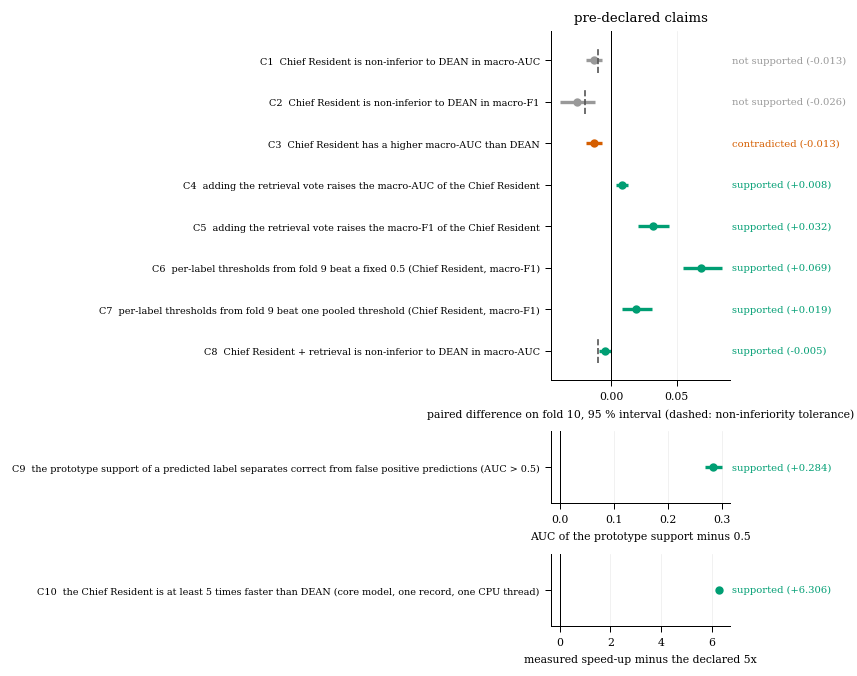

In [35]:
# ---- Figure 20: the claims ------------------------------------------------------------------------------------------------------------
VC = {'supported': '#009E73', 'not supported': '#999999', 'contradicted': '#D55E00'}
grp = [CLAIMS[CLAIMS.metric.isin(['macro AUC', 'macro F1'])], CLAIMS[CLAIMS.metric == 'AUC - 0.5'], CLAIMS[CLAIMS.metric == 'speed-up minus tolerance']]
grp = [g for g in grp if len(g)]
fig, axs = plt.subplots(len(grp), 1, figsize=(W2, 0.36 * len(CLAIMS) + 0.45 * len(grp) + 0.7), gridspec_kw=dict(height_ratios=[len(g) + 0.8 for g in grp]))
axs = np.atleast_1d(axs)
xl = {0: 'paired difference on fold 10, 95 % interval (dashed: non-inferiority tolerance)', 1: 'AUC of the prototype support minus 0.5', 2: 'measured speed-up minus the declared 5x'}
for k, (ax, g) in enumerate(zip(axs, grp)):
    g = g.reset_index(drop=True)
    for i, r in g.iterrows():
        y_ = len(g) - 1 - i
        ax.plot([r['lo'], r['hi']], [y_, y_], color=VC[r['verdict']], lw=2.0, solid_capstyle='butt'); ax.plot(r['delta'], y_, 'o', color=VC[r['verdict']], ms=4)
        if r['margin'] > 0: ax.plot([-r['margin']] * 2, [y_ - 0.3, y_ + 0.3], color='#555555', lw=1.0, ls='--')
        ax.text(1.01, y_, f'{r["verdict"]} ({r["delta"]:+.3f})', transform=ax.get_yaxis_transform(), fontsize=6, va='center', color=VC[r['verdict']])
    ax.axvline(0, color='black', lw=0.6); ax.set_yticks(range(len(g))); ax.set_yticklabels([f'{r.id}  {r.claim}' for r in g.iloc[::-1].itertuples()], fontsize=5.8)
    ax.set_ylim(-0.7, len(g) - 0.3); ax.set_xlabel(xl[k], fontsize=6.5); ax.grid(axis='y', alpha=0)
axs[0].set_title('pre-declared claims')
fig.tight_layout(); save_fig(fig, 'fig20_claims')

## 13. Checks, results and export

In [36]:
check('fold-10 labels were loaded exactly once during the whole run', _TEST_ACCESS['n'] == 1, _TEST_ACCESS['n'])
check('the frozen configuration is unchanged at the end of the run', sha256(FZ_PATH) == FZ_SHA)
check('every model file is unchanged (hashes of the frozen configuration)', sha256(P_DEPLOY) == FROZEN['hashes']['deploy'] and sha256(idx_path('trainval')) == FROZEN['hashes']['index_trainval'])
check('the Chief Resident reproduces the fold-9 AUC that Stage 8 stored (within 0.003)', abs(float(np.nanmean(AUC_CR_VA[REL_VAL])) - float(PAY['val_macro_auc'])) < 0.003 if 'val_macro_auc' in PAY else True, f'{np.nanmean(AUC_CR_VA[REL_VAL]):.4f} vs {PAY.get("val_macro_auc", float("nan")):.4f}', level='warn')
check('test AUC of the Chief Resident is in the range expected from fold 9 (within 0.05)', abs(macro_pt(A_PT[CR_], 'all') - float(np.nanmean(AUC_CR_VA[REL_HEAD]))) < 0.05, f'test {macro_pt(A_PT[CR_], "all"):.4f}, fold 9 {np.nanmean(AUC_CR_VA[REL_HEAD]):.4f}', level='warn')
check('bootstrap intervals contain the point estimates', all((MAIN['auc_lo'] <= MAIN['macro_auc'] + 1e-9) & (MAIN['macro_auc'] <= MAIN['auc_hi'] + 1e-9) & (MAIN['f1_lo'] <= MAIN['macro_f1'] + 1e-9) & (MAIN['macro_f1'] <= MAIN['f1_hi'] + 1e-9)))
check('test records equal the number of fold-10 records and nothing was dropped', len(PT[CR_]) == NTE == int((fold == 10).sum()))
check('all 20 figures were written (png and pdf)', len(glob.glob(os.path.join(FIG_DIR, '*.png'))) == 20 and len(glob.glob(os.path.join(FIG_DIR, '*.pdf'))) == 20, len(glob.glob(os.path.join(FIG_DIR, '*.png'))))
CHK = pd.DataFrame(CHECKS); CHK.to_csv(os.path.join(TAB_DIR, 'checks.csv'), index=False)
with pd.option_context('display.max_colwidth', 110, 'display.width', 240): print(CHK[['check', 'status']].to_string(index=False))
nfail, nwarn = int((CHK.status == 'FAIL').sum()), int((CHK.status == 'WARN').sum())
print(f'\n{int((CHK.status == "PASS").sum())} pass, {nwarn} warn, {nfail} fail')
if CFG['strict'] and nfail: raise AssertionError(f'{nfail} check(s) failed, see the table above')
CLAIMS.to_csv(os.path.join(TAB_DIR, 'claims.csv'), index=False)

[ok] fold-10 labels were loaded exactly once during the whole run: 1
[ok] the frozen configuration is unchanged at the end of the run
[ok] every model file is unchanged (hashes of the frozen configuration)
[ok] the Chief Resident reproduces the fold-9 AUC that Stage 8 stored (within 0.003): 0.9125 vs 0.9125
[ok] test AUC of the Chief Resident is in the range expected from fold 9 (within 0.05): test 0.9061, fold 9 0.9096
[ok] bootstrap intervals contain the point estimates
[ok] test records equal the number of fold-10 records and nothing was dropped
[ok] all 20 figures were written (png and pdf): 20
                                                                                           check status
                             deployed model and DEAN share the label order and the normalisation   PASS
                                                    deploy file holds no training-only parameter   PASS
                                   split: train = folds 1-8, validation = fold 9, 

In [37]:
shutil.copy(P_DEPLOY, os.path.join(WORK, 'chief_resident_deploy.pt')) if os.path.abspath(P_DEPLOY) != os.path.join(WORK, 'chief_resident_deploy.pt') else None
json.dump(dict(pipeline='hidmamba_infer.HiDMambaPipeline', files={'chief_resident_deploy.pt': FROZEN['hashes']['deploy'], 'dean_finetuned.pt (dean-finetuned-v2)': FROZEN['hashes']['dean'],
          'index_trainval (prototype-index-v1)': FROZEN['hashes']['index_trainval'], 'prototype_meta.npz (prototype-index-v1)': FROZEN['hashes']['prototype_meta'], 'frozen_config.json': FZ_SHA},
          python_files=['hidmamba_infer.py', 'cr_lib.py', 'dean_lib.py', 'proto_lib.py'], usage="pipe = HiDMambaPipeline(dict(deploy=..., dean=..., frozen='frozen_config.json', index_root=...), device='cpu'); pipe.predict(ecg_12x1000)"),
          open(os.path.join(WORK, 'deployment_manifest.json'), 'w'), indent=1)
M = lambda n, sc='all': MAIN[(MAIN.system == n) & (MAIN.scope == sc)].iloc[0]
METRICS = dict(
    versions=VERSIONS, hardware=HW, frozen_sha256=FZ_SHA, test_label_loads=_TEST_ACCESS['n'], n_test=NTE, n_val=NVA, headline_labels=[LABELS[i] for i in np.where(REL_HEAD)[0]],
    left_out=[LABELS[i] for i in np.where(~REL_HEAD)[0]], main=MAIN.to_dict('records'), sensitivity_all_labels=SENS.to_dict('records'), record_level=REC.reset_index().rename(columns={'index': 'system'}).to_dict('records'),
    hierarchy_violation_rate=VIOL, threshold_rules_test={k: dict(macro_f1=macro_pt(FR_PT[k], 'all'), ci=[float(np.percentile(macro_bt(FR_BT[k], 'all'), 2.5)), float(np.percentile(macro_bt(FR_BT[k], 'all'), 97.5))]) for k in FR_PT},
    threshold_rules_val_crossfit=XF_RULES.reset_index().rename(columns={'index': 'system'}).to_dict('records'), threshold_spread_iqr_median=float(np.median(SPREAD[REL_VAL])),
    diagnostic_threshold_transfer=dict(macro_f1_frozen=macro_pt(F_PT[CR_], 'all'), macro_f1_refit_on_test=macro_pt(F1_OR, 'all'), note='diagnostic only, never reported as performance'),
    calibration_test=ECE_TE, fusion=dict(alpha=ALPHA, val_crossfit_gain=FUS_XF_GAIN, test_macro_auc_index_trainval=macro_pt(A_PT[FU_], 'all'), test_macro_auc_index_train=float(np.nanmean(A_FUS_TR[REL_HEAD]))),
    explanation=dict(auc_support=AUC_SUP, auc_support_ci=[float(np.nanpercentile(bs_sup, 2.5)), float(np.nanpercentile(bs_sup, 97.5))], auc_model_probability=AUC_PROB, auc_similarity_for_exact=float(AUC_SIM),
                     top1_jaccard=float(J1.mean()), random_jaccard=J_CH, median_lift_at_10=float(np.nanmedian(LIFT[REL_HEAD])), support_table=SUPT.to_dict('records')),
    claims=CLAIMS.to_dict('records'), latency_core=LAT.to_dict('records'), latency_end_to_end=E2E.to_dict('records'), speedup={f'{k[0]} bs{k[1]}': v for k, v in SPEED.items()},
    parameters=dict(chief_resident=N_PARAMS_CR, dean=N_PARAMS_DEAN), checks=dict(pass_=int((CHK.status == 'PASS').sum()), warn=nwarn, fail=nfail), runtime_minutes=(time.time() - NB_T0) / 60)
json.dump(METRICS, open(os.path.join(WORK, 'stage10_metrics.json'), 'w'), indent=1, default=float)

def vd(cid): return CLAIMS[CLAIMS.id == cid].iloc[0]
L = []
c_ = M(CR_); d_ = M(DE_); f_ = M(FU_)
L.append(f'On the held-out fold 10 ({NTE} records, {int(REL_HEAD.sum())} labels with at least {CFG["min_pos"]} positives in folds 9 and 10), the deployed Chief Resident ({N_PARAMS_CR / 1e6:.2f} M parameters) reaches a macro-F1 of {c_.macro_f1:.3f} '
         f'(95 % interval {c_.f1_lo:.3f} to {c_.f1_hi:.3f}) with per-label thresholds fixed on fold 9, and a macro-AUC of {c_.macro_auc:.3f} ({c_.auc_lo:.3f} to {c_.auc_hi:.3f}). The same numbers for the {N_PARAMS_DEAN / 1e6:.1f} M-parameter DEAN are '
         f'{d_.macro_f1:.3f} and {d_.macro_auc:.3f}.')
for cid in ('C1', 'C2', 'C3'):
    r = vd(cid); L.append(f'{r["claim"]}: difference {r["delta"]:+.4f} [{r["lo"]:+.4f}, {r["hi"]:+.4f}]' + (f' against a tolerance of {r["margin"]:g}' if r['margin'] else '') + f', {r["verdict"]}.')
r4, r5 = vd('C4'), vd('C5')
L.append(f'Adding the neighbour vote (a = {ALPHA:g}) gives a macro-AUC of {f_.macro_auc:.3f} and a macro-F1 of {f_.macro_f1:.3f}: AUC change {r4["delta"]:+.4f} [{r4["lo"]:+.4f}, {r4["hi"]:+.4f}] ({r4["verdict"]}), F1 change {r5["delta"]:+.4f} [{r5["lo"]:+.4f}, {r5["hi"]:+.4f}] ({r5["verdict"]}).')
r6, r7 = vd('C6'), vd('C7')
L.append(f'Per-label thresholds from fold 9 against a fixed 0.5: {r6["delta"]:+.4f} [{r6["lo"]:+.4f}, {r6["hi"]:+.4f}] ({r6["verdict"]}); against one pooled threshold: {r7["delta"]:+.4f} [{r7["lo"]:+.4f}, {r7["hi"]:+.4f}] ({r7["verdict"]}).')
r9 = vd('C9'); L.append(f'The prototype lookup is a usable explanation to the extent that the retrieved ECGs share the predicted diagnosis: the nearest prototype shares {J1.mean():.2f} of the labels on average (random ECG {J_CH:.2f}), and the fraction of the {ks} prototypes carrying a predicted label separates correct from false predictions with an AUC of {AUC_SUP:.3f} ({r9["verdict"]}).')
L.append(f'Latency of the core model on one CPU thread: {l_cr:.1f} ms (DEAN {l_de:.1f} ms, {l_de / l_cr:.1f} times slower); end to end with the prototype lookup {l_e2e:.1f} ms.')
print('\n'.join('* ' + l for l in L)); open(os.path.join(WORK, 'stage10_results_draft.txt'), 'w').write('\n'.join(L))
shutil.rmtree(os.path.join(WORK, '__pycache__'), ignore_errors=True)
print(f'\ntotal notebook time {(time.time() - NB_T0) / 60:.1f} min')
for f in sorted(os.listdir(WORK)):
    p = os.path.join(WORK, f)
    if os.path.isfile(p): print(f'  {f:34s} {os.path.getsize(p) / 1e6:8.2f} MB')

* On the held-out fold 10 (2198 records, 20 labels with at least 10 positives in folds 9 and 10), the deployed Chief Resident (0.89 M parameters) reaches a macro-F1 of 0.521 (95 % interval 0.503 to 0.540) with per-label thresholds fixed on fold 9, and a macro-AUC of 0.906 (0.894 to 0.917). The same numbers for the 11.5 M-parameter DEAN are 0.548 and 0.919.
* Chief Resident is non-inferior to DEAN in macro-AUC: difference -0.0133 [-0.0195, -0.0069] against a tolerance of 0.01, not supported.
* Chief Resident is non-inferior to DEAN in macro-F1: difference -0.0265 [-0.0397, -0.0124] against a tolerance of 0.02, not supported.
* Chief Resident has a higher macro-AUC than DEAN: difference -0.0133 [-0.0195, -0.0069], contradicted.
* Adding the neighbour vote (a = 0.6) gives a macro-AUC of 0.915 and a macro-F1 of 0.553: AUC change +0.0084 [+0.0037, +0.0129] (supported), F1 change +0.0323 [+0.0204, +0.0441] (supported).
* Per-label thresholds from fold 9 against a fixed 0.5: +0.0690 [+0.0546,

## After this notebook
1. **Publish** `/kaggle/working` as the Dataset `final-evaluation-v1`. `stage10_metrics.json`, `claims.csv`, `test_main_results.csv` and the figures are what the paper's results section is written from.
2. **Read `claims.csv` first.** It decides what the paper may say. A claim that is *not supported* is reported as such; the data not deciding is a finding, not a failure.
3. **Do not run this notebook again with different settings to improve a number.** The fold-10 labels have been read once; a second evaluation after changing anything would no longer be a held-out evaluation. If something must change, the honest course is to say so in the paper and report both.
4. **Report all four systems.** The Chief Resident is the headline; DEAN is the reference; CR + retrieval and the explanation analysis (Section 10) are what the prototype lookup contributes.
5. **Deployment.** `hidmamba_infer.py` plus `deployment_manifest.json` is the Step-11 pipeline; it was checked here against the batch evaluation.